In [41]:
#Import functions in library
import time
import numpy as np
import matplotlib.pyplot as plt
import warnings
from matplotlib import MatplotlibDeprecationWarning
warnings.filterwarnings("ignore", category=MatplotlibDeprecationWarning, message=(r"The (width|height|x|y|x0|y0|x1|y1) parameter as float " r"was deprecated in Matplotlib 3\.10.*"))
from matplotlib.cbook import get_sample_data
from scipy import integrate, stats
from mp3lib import (sample_mean_cov, is_valid_covariance, gaussian_pdf, whitening_matrix, lmmse_weights, covariance_factor, pca_analysis)

#Use SEED number
SEED = 1506714529 # drawn 2026-11-09, do not change
rng = np.random.default_rng(SEED)

#Generate one independent random-number generator for each step
rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]
rng_step7 = rng.spawn(1)[0]
rng_step8 = rng.spawn(1)[0]
rng_bonusA = rng.spawn(1)[0]
rng_bonusB = rng.spawn(1)[0]

np.set_printoptions(precision=6, suppress=True)

## Step 1

Get the mechanics of joint, marginal, and conditional densities working
with (X, Y) Joint density 𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦, 0 ≤ 𝑥 ≤ 1, 0 ≤ 𝑦 ≤ 1

Valid Densities must be nonnegative and integrate to 1

x + y ≥ 0 $\int_{0}^{1}\int_{0}^{1} (x + y) \,dy\,dx$ 

= $\int_{0}^{1} (x + {[(1^2)/2]-[(0^2)/2]}) \,dx$ 

= $\int_{0}^{1} (x + 1/2) \,dx$ 

= [(1^2)/2] + (1/2)1 - {[(0^2)/2] + (1/2)0}

= 1/2 + 1/2 = 1

Thus, the density is valid because it is nonnegative and it integrates to 1.



In [2]:
#Confirm the Density is valid numerically using a 2D quadrature
def joint_pdf_xy(x, y):
    if 0 <= x <= 1 and 0 <= y <= 1:
        return x + y
    return 0.0
joint_integral, joint_quad_error = integrate.dblquad(lambda y, x: x + y, 0, 1, lambda x: 0, lambda x: 1)
print(f"Joint-density integral = {joint_integral:.10f}")
print(f"Quadrature estimated absolute error = {joint_quad_error:.3e}")

Joint-density integral = 1.0000000000
Quadrature estimated absolute error = 1.663e-14


Derive both marginals

$ 𝑓_𝑋(𝑥) $ = $\int_{-∞}^{∞} 𝑓_{𝑋𝑌} (𝑥, 𝑦) \,dy$

$ 𝑓_𝑋(𝑥) $ = $\int_{0}^{1} (x + y) \,dy$

= [xy + (y^2)/2] y = 1 and 0

= [x(1) + (1^2)/2] - [x(0) + (0^2)/2]

$ 𝑓_𝑋(𝑥) $ = {x + 1/2, 0 ≤ 𝑥 ≤ 1
        
         0, otherwise}
$ 𝑓_𝑋(.3) $ = .3 + .5 = .8 

<br>
<br>
<br>
$ 𝑓_Y(y) $ = $\int_{0}^{1} (x + y) \,dx$

= [xy + (x^2)/2] x = 1 and 0

= [y(1) + (1^2)/2] - [y(0) + (0^2)/2]

$ 𝑓_Y(y) $ = {y + 1/2, 0 ≤ y ≤ 1

         0, otherwise}

Thus, outside [0,1] both marginal densities are 0

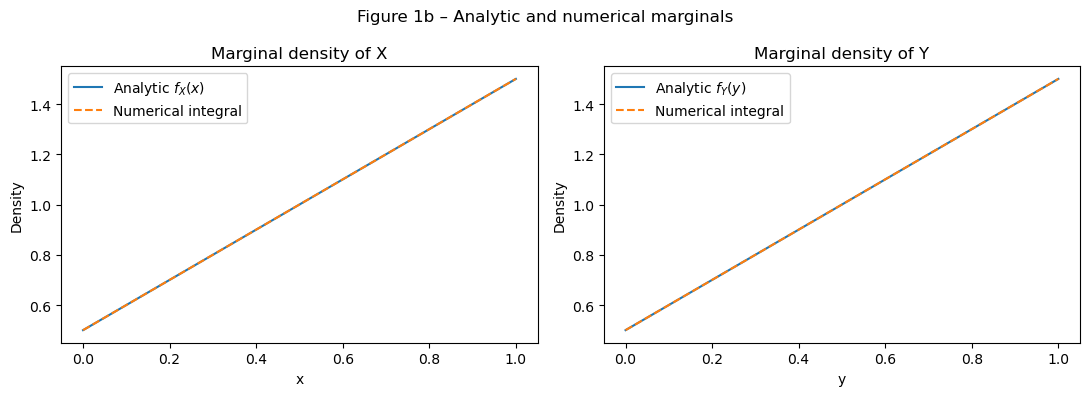

Maximum marginal-grid error: 8.881784197001252e-16


In [3]:
#Confirm numerically by integrating joint density 
grid = np.linspace(0, 1, 501)
Xg, Yg = np.meshgrid(grid, grid, indexing="xy")
Zg = Xg + Yg
fx_analytic = grid + 0.5
fy_analytic = grid + 0.5
#Integrate the joint density along the other coordinate
fx_numeric = np.trapezoid(Zg, grid, axis=0)   #integrate over y, retain x
fy_numeric = np.trapezoid(Zg, grid, axis=1)   #integrate over x, retain y
#Plot data
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(grid, fx_analytic, label="Analytic $f_X(x)$")
ax[0].plot(grid, fx_numeric, "--", label="Numerical integral")
ax[0].set(title="Marginal density of X", xlabel="x", ylabel="Density")
ax[0].legend()
ax[1].plot(grid, fy_analytic, label="Analytic $f_Y(y)$")
ax[1].plot(grid, fy_numeric, "--", label="Numerical integral")
ax[1].set(title="Marginal density of Y", xlabel="y", ylabel="Density")
ax[1].legend()
fig.suptitle("Figure 1b – Analytic and numerical marginals")
plt.tight_layout()
plt.show()
print("Maximum marginal-grid error:",
      max(np.max(np.abs(fx_numeric-fx_analytic)),
          np.max(np.abs(fy_numeric-fy_analytic))))

After integrating the joint probability denisty function 𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦 over the variable that wasn't considered we obtained x + 1/2 for 0 ≤ 𝑥 ≤ 1 and y + 1/2 for 0 ≤ y ≤ 1 with 0 otherwise for both. Therefore, when x = .3, then fX(.3) = .3 + .5 = .8. Thus, one may see that both marginal densities are defined over the interval [0,1] with 0 elsewhere. To confirm the result, numerical integration was used and as we can see by the graphs that both curves closely overlap, which proves that the integration agrees with the derivations. Therefore, after calculating max marginal error, we obtained a 8.88 x 10^-16, which is small enough to demonstrate a success in our data and prove that both results are similar. After all, the small error was due to the finite spacing in the graph and the numerical integration through trapezoid. Since both graphs have an increasing linear shape, we can deduce that higher X and Y values have a higher marginal probablity density than lower values. For instance, when X is 1/2, then the marginal density is 1. Although the marginal densities describe each variable individually, the joint density describes the relationship between both variables.

Derive conditional density of Y given X = x

$\ f_{Y|X}(y|x) = \frac{f_{XY}(x,y)}{f_X(x)} = \frac{x+y}{x+1/2},\quad0\leq y\leq1 \$

At x = .3 

$\ f_{Y|X}(y|0.3) = \frac{0.3+y}{0.8},\quad0\leq y\leq1 \$

$\ \int_0^1\frac{0.3+y}{0.8}dy = \frac{0.3+0.5}{0.8} = 1 \$

It integrates to 1 because it is a conditional density.

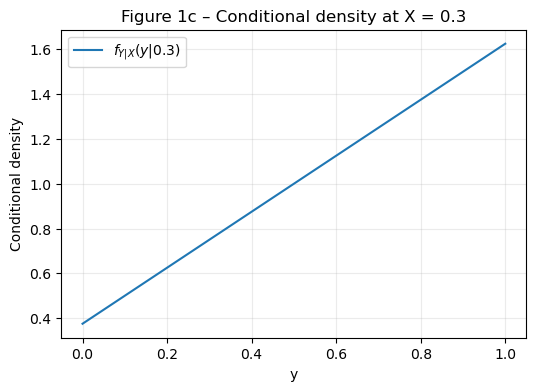

Conditional density integral = 1.00000000


In [4]:
#Plot of conditional density at x = .3
x0 = 0.3
conditional = (x0 + grid) / (x0 + 0.5)
conditional_integral = np.trapezoid(conditional, grid)
plt.figure(figsize=(6, 4))
plt.plot(grid, conditional, label=r"$f_{Y|X}(y|0.3)$")
plt.xlabel("y")
plt.ylabel("Conditional density")
plt.title("Figure 1c – Conditional density at X = 0.3")
plt.legend()
plt.grid(alpha=0.25)
plt.show()
print(f"Conditional density integral = {conditional_integral:.8f}")

The graph above is a plot of conditional density at x = .3, which indicates the relationship between X and Y given x = .3. As one can see by the graph, the conditional density increases linearly as y increases from 0 to 1, with the value starting at .375 and ending at 1.625. After the conditional density was integrated over the interval [0,1], we obtained 1, which indicates that the total area is 1. Thus, the conditional PDF is valid and shows the relationship between X and Y. 

Through symmetry E[X] = E[Y]

$\ E[X] = \int_0^1\int_0^1 x(x+y) dy dx
 = \int_0^1(x^2+x/2) dx = \frac13+\frac14 = \frac7{12} \$

$\ E[X] = \frac7{12} = .583333 \$

<br>
<br>

$\ E[Y] = \int_0^1\int_0^1 y(x+y) dx dy
 = \int_0^1(y^2+y/2) dy = \frac13+\frac14 = \frac7{12} \$

$\ E[Y] = \frac7{12} = .583333 \$

<br>
<br>

$\ E[XY] = \int_0^1\int_0^1 xy(x+y) dy dx = \int_0^1\int_0^1 (x^2y+xy^2) dx dy = \frac16+\frac16 = \frac13 \$

$\ E[XY] = \frac13 \$

<br>
<br>

$\ E[X^2] = \int_0^1\int_0^1 x^2(x+y) dy dx
 = \int_0^1(x^3+(x^2)/2) dx = \frac14+\frac16 = \frac5{12} \$

$\ Var(X) = E[X^2] - E[X]^2 = \frac5{12} - (\frac7{12})^2 = \frac{11}{144} \$

$\ Var(X) = \frac{11}{144} = .0763889 \$

<br>
<br>

$\ Cov(X,Y) = E[XY]-E[X]E[Y] = \frac13-\frac{49}{144} = -\frac1{144} \$

$\ Cov(X,Y) = -\frac1{144} = -0.00694444 \$

<br>
<br>

Correlation Coeffient

Through symmetry Var(X) = Var(Y)

$\ Var(Y) = \frac{11}{144} = .0763889 \$

$\ \rho = \frac{Cov(X,Y)}{\sqrt{(Var(X))(Var(Y))}} = \frac{-1/144}{\sqrt{(11/144)(11/144)}} = -\frac1{11} \$

$\ \rho = -\frac1{11} = -0.0909091 \$


In [5]:
EX = EY = 7/12
EXY = 1/3
varX = varY = 11/144
covXY = -1/144
rhoXY = -1/11

#Numerical quadrature of the raw moments
quad_EX = integrate.dblquad(lambda y, x: x*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EY = integrate.dblquad(lambda y, x: y*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EXY = integrate.dblquad(lambda y, x: x*y*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EX2 = integrate.dblquad(lambda y, x: x*x*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_EY2 = integrate.dblquad(lambda y, x: y*y*(x+y), 0, 1, lambda x: 0, lambda x: 1)[0]
quad_varX = quad_EX2 - quad_EX**2
quad_varY = quad_EY2 - quad_EY**2
quad_cov = quad_EXY - quad_EX*quad_EY
quad_rho = quad_cov / np.sqrt(quad_varX*quad_varY)
print("Analytic: EX = EY = 7/12, EXY = 1/3, VarX = VarY = 11/144,")
print("          CovXY = -1/144, rho = -1/11")
print(f"Quadrature: EX = {quad_EX:.8f}, EY = {quad_EY:.8f}, EXY = {quad_EXY:.8f}")
print(f"            VarX = {quad_varX:.8f}, VarY = {quad_varY:.8f}")
print(f"            CovXY = {quad_cov:.8f}, rho = {quad_rho:.8f}")

Analytic: EX = EY = 7/12, EXY = 1/3, VarX = VarY = 11/144,
          CovXY = -1/144, rho = -1/11
Quadrature: EX = 0.58333333, EY = 0.58333333, EXY = 0.33333333
            VarX = 0.07638889, VarY = 0.07638889
            CovXY = -0.00694444, rho = -0.09090909


After verifying each value by quadrature, one can see that the values are similar, which proves the relationships between the X and Y values.  

Acceptance rate and bounding constant

Bounding constant M:

𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦, 0 ≤ 𝑥 ≤ 1, 0 ≤ 𝑦 ≤ 1

max occurs when x = 1 and y = 1

Thus, when 𝑓𝑋𝑌 (1, 1) = 1 + 1 = 2

Therefore, M = 2

Acceptance rate: 

$\ P(accept) = \frac{1}{M}\int_0^1\int_0^1 (x+y) dy dx \$

 = $\ \frac{1}{2}\int_0^1 (x1+(1^2)/2) - [(x0+(0^2)/2)] dx \$

 = $\ \frac{1}{2}\int_0^1 (x+1/2) dx \$

 = $\ \frac{1}{2} {[(1^2)/2]+[(1/2)(1)]} \$

 = $\ \frac{1}{2} (1) \$

 = P(accept) = 1/2 = 50%


In [6]:
N1 = 1_000_000
accepted = []
n_proposed = 0
while sum(a.shape[0] for a in accepted) < N1:
    remaining = N1 - sum(a.shape[0] for a in accepted)
    batch = max(100_000, int(2.2*remaining))
    proposal = rng_step1.random((batch, 2))
    keep = rng_step1.random(batch) < proposal.sum(axis=1)/2
    accepted.append(proposal[keep])
    n_proposed += batch
samples1 = np.concatenate(accepted, axis=0)[:N1]
x1, y1 = samples1.T
n_accepted_total = sum(a.shape[0] for a in accepted)
acceptance_rate = n_accepted_total / n_proposed

#call mean_se function to calculate standard error
def mean_se(a):
    return np.std(a, ddof=1) / np.sqrt(a.size)
mX, mY = x1.mean(), y1.mean()
mXY = (x1*y1).mean()
vX, vY = x1.var(ddof=1), y1.var(ddof=1)
cXY = np.cov(x1, y1, ddof=1)[0, 1]

#Influence values for variance and covariance estimators
ifx = (x1-mX)**2 - vX
ify = (y1-mY)**2 - vY
ifcov = (x1-mX)*(y1-mY) - cXY
print(f"Accepted N={N1:,}; proposals={n_proposed:,}; acceptance={acceptance_rate:.4f}")
print("Statistic   estimate    theory    difference  estimated SE")
rows = [("E[X]", mX, EX, mX-EX, mean_se(x1)),
    ("E[Y]", mY, EY, mY-EY, mean_se(y1)),
    ("E[XY]", mXY, EXY, mXY-EXY, mean_se(x1*y1)),
    ("Var(X)", vX, varX, vX-varX, mean_se(ifx)),
    ("Var(Y)", vY, varY, vY-varY, mean_se(ify)),
    ("Cov(X,Y)", cXY, covXY, cXY-covXY, mean_se(ifcov)),]
for name, est, theory, diff, se in rows:
    print(f"{name:10s} {est: .7f}  {theory: .7f}  {diff: .3e}  {se:.3e}")
#Calculate sample correlation
rho_sample = np.corrcoef(x1, y1)[0, 1]
#Calculate difference from theoretical correlation
rho_difference = rho_sample - rhoXY
rho_abs_difference = abs(rho_difference)
#Center the samples
x_centered = x1 - x1.mean()
y_centered = y1 - y1.mean()
#Standardize the samples
u = x_centered / np.std(x1, ddof=1)
v = y_centered / np.std(y1, ddof=1)
#Calculate influence values for correlation
ifrho = u*v - (rho_sample/2)*(u**2 + v**2)
#Estimate standard error
se_rho = np.std(ifrho, ddof=1) / np.sqrt(N1)
print("\nCorrelation statistics:")
print(f"Sample correlation:       {rho_sample:.8f}")
print(f"Theoretical correlation:  {rhoXY:.8f}")
print(f"Absolute difference:      {rho_abs_difference:.3e}")
print(f"Estimated standard error: {se_rho:.3e}")

Accepted N=1,000,000; proposals=2,200,000; acceptance=0.4998
Statistic   estimate    theory    difference  estimated SE
E[X]        0.5835585   0.5833333   2.252e-04  2.763e-04
E[Y]        0.5836628   0.5833333   3.294e-04  2.762e-04
E[XY]       0.3337121   0.3333333   3.787e-04  2.357e-04
Var(X)      0.0763605   0.0763889  -2.842e-05  7.642e-05
Var(Y)      0.0762715   0.0763889  -1.174e-04  7.622e-05
Cov(X,Y)   -0.0068893  -0.0069444   5.515e-05  7.472e-05

Correlation statistics:
Sample correlation:       -0.09027327
Theoretical correlation:  -0.09090909
Absolute difference:      6.358e-04
Estimated standard error: 9.708e-04


After generating 10^6 samples from the joint density we obtained an acceptance rate of around .49, which was expected because the theoretical acceptance rate was .5 or 50% of the samples. After all, from the 2,200,000 proposals, only 1,000,000 were accepted. To obtain the bounding constant of 2, we used the max value of the joint PDF 𝑓𝑋𝑌 (𝑥, 𝑦) = 𝑥 + 𝑦, which was x = 1 and y = 1. That gave us the value 2, which was our bounding constant. Therefore, during rejection sampling, the points were generated uniformly and were accepted uniformly when the random number was less than or equal to (x + y)/2. As far as the rest of the statistics go, we were able to notice that the values were similar between the theoretical and experimental with 10^6 samples with a small standard error, which was acceptable because of how closely related the values were to each other. After all, for the Cov(X,Y), the theoretical value was -0.0069444 with and experimental value being -0.0069092 for 10^6 samples and a standard error of 7.471e-05. In conclusion, the small standard error was due to the different number of values of the samples that were taken in the experiment.

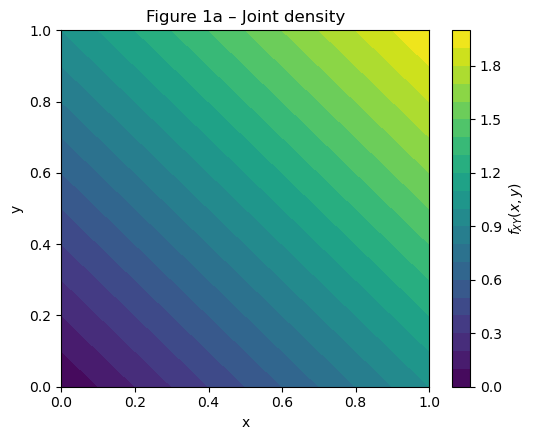

In [7]:
#plot Joint Density
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cont = ax.contourf(Xg, Yg, Zg, levels=20, cmap="viridis")
fig.colorbar(cont, ax=ax, label=r"$f_{XY}(x,y)$")
ax.set(xlabel="x", ylabel="y", title="Figure 1a – Joint density")
plt.tight_layout()
plt.show()

The figure 1a shows joint PDF of X and Y over the unit square where both variables range from 0 to 1 with the denisty increasing linearly in both directions. The lowest density occurs at (0,0) and the highest occurs at (1,1)  with a density of 2. Thus, the intensity becomes hogher toward the upper right corner, which indicates the combination of large values for both variables. Therefore, the joint density shows symmetry across the diagonal x=y with the color intensity representing the value of the joint density.

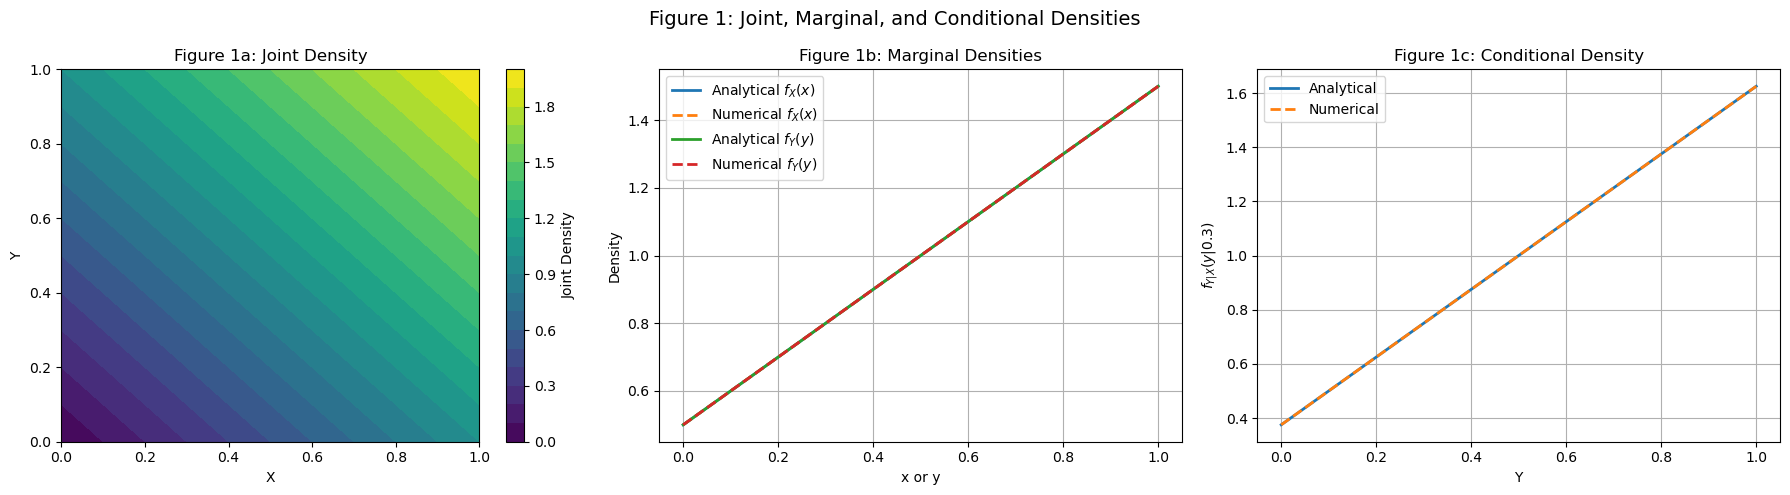

Figure 1 Numerical Verification
--------------------------------
Numerical integral of conditional density: 1.000000
Analytical integral of conditional density: 1.000000
f_X(0.3) analytical: 0.800000
f_X(0.3) numerical: 0.800000


In [8]:
import numpy as np
import matplotlib.pyplot as plt

#STEP 1: FIGURE 1 - THREE PANELS
#Create a grid over the unit square
x = np.linspace(0, 1, 201)
y = np.linspace(0, 1, 201)
X, Y = np.meshgrid(x, y)
#Joint probability density function
f_xy = X + Y
#Numerical marginal densities using trapezoidal integration
#Integrate over y to obtain f_X(x)
f_x_numerical = np.trapezoid(f_xy, y, axis=0)
#Integrate over x to obtain f_Y(y)
f_y_numerical = np.trapezoid(f_xy, x, axis=1)
#Analytical marginal densities
f_x_analytical = x + 0.5
f_y_analytical = y + 0.5

x_given = 0.3
#Analytical conditional density
f_y_given_x = (x_given + y) / (x_given + 0.5)
#Numerical conditional density using numerical marginal
f_y_given_x_numerical = (x_given + y) / np.trapezoid(x_given + y, y)
#Verify conditional density integrates to 1
conditional_integral = np.trapezoid(f_y_given_x, y)

#CREATE THREE-PANEL FIGURE
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#FIGURE 1A: JOINT DENSITY
contour = axes[0].contourf(X, Y, f_xy, levels=20, cmap="viridis")
fig.colorbar(contour, ax=axes[0], label="Joint Density")
axes[0].set_title("Figure 1a: Joint Density")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")

#FIGURE 1B: MARGINALS
#Analytical and numerical marginal of X
axes[1].plot(x, f_x_analytical, label="Analytical $f_X(x)$", linewidth=2)
axes[1].plot(x, f_x_numerical, "--", label="Numerical $f_X(x)$", linewidth=2)

#Analytical and numerical marginal of Y
axes[1].plot(y, f_y_analytical, label="Analytical $f_Y(y)$", linewidth=2)
axes[1].plot(y, f_y_numerical, "--", label="Numerical $f_Y(y)$", linewidth=2)
axes[1].set_title("Figure 1b: Marginal Densities")
axes[1].set_xlabel("x or y")
axes[1].set_ylabel("Density")
axes[1].legend()
axes[1].grid(True)

#FIGURE 1C: CONDITIONAL
axes[2].plot(y, f_y_given_x, label="Analytical", linewidth=2)
axes[2].plot(y, f_y_given_x_numerical, "--", label="Numerical", linewidth=2)
axes[2].set_title("Figure 1c: Conditional Density")
axes[2].set_xlabel("Y")
axes[2].set_ylabel(r"$f_{Y|X}(y|0.3)$")
axes[2].legend()
axes[2].grid(True)

#Overall figure title
fig.suptitle("Figure 1: Joint, Marginal, and Conditional Densities", fontsize=14)
plt.tight_layout()
plt.show()
print("Figure 1 Numerical Verification")
print("--------------------------------")
print(f"Numerical integral of conditional density: "
      f"{conditional_integral:.6f}")
print(f"Analytical integral of conditional density: 1.000000")
print(f"f_X(0.3) analytical: {0.3 + 0.5:.6f}")
print(f"f_X(0.3) numerical: "
      f"{np.interp(0.3, x, f_x_numerical):.6f}")

The following is all plots that were determined before next to each other with some verifications to show that are expected values were correct. Therefore, they show the Joint, Marginal, and Conditional Densities that were calculated and explained before in the previous cells. In the joint density figure, the color intensity represents the joint density, in the marginal density figure, both f_X(x) and f_Y(y) overlap, which indicates their individual similarities, and in the conditional density figure, the density increases linearly from .375 to 1.625 over the interval [0,1]

The correlation is small and negative, which makes X and Y pull against each other because the joint density f_X,Y(x,y) = x+y increases as either X or Y increases, but gives more weight when one variable is high while the other is low, which is seen in the top right corner of the joint density shape. Therefore, this is expected because the effects of the variables are independent, which causes a weak tendency for the variables to move in opposite directions and a weak negative linear relationship that results in a negative correlation of ρ = -1/11 = -0.0909.

## Step 2

Given  X is a uniform, continuous distribution on (-1,1), and Y = $X^2$, we can find their covarience.

Covarience is defined as $$Cov(X,Y) = E{(X-\mu_x)(Y-\mu_Y)}$$

However, an easier way of writing this formula would be $$Cov(X,Y) = E(X,Y) - E(X)E(Y)$$, which I derive below from the original form.  

This is found from cross multiplying the original formula and taking $E({\mu}_X)$ or $E({\mu}_Y)$ to equal ${\mu}_X$ and ${\mu}_Y$, respectively, as the expected value of the mean is itself.  In addition, $E({\mu}_X{\mu}_Y)$ would be equal to ${\mu}_X {\mu}_Y$ by the same principle.  From there, when we distribute $(X-\mu_x)(Y-\mu_Y)$ within $E()$, we get $E(XY-\mu_YX-\mu_xY+\mu_x\mu_y)$.  Taking the varience of each of these terms $E(XY) - E(\mu_YX) - E(\mu_xY) - E(\mu_x\mu_y)$.  From our earlier statements, we can move the $\mu_X$ and $\mu_y$ terms outside the funcion E() in the terms $E(\mu_YX)$ and $E(\mu_xY)$ and write this as  $E(XY) - \mu_X\mu_Y - \mu_X\mu_Y + \mu_X\mu_Y$.  Cancelling the two identical terms, we get our final form $$Cov(X,Y) = E(X,Y) - E(X)E(Y)$$.

So, to solve for the covarience, we find the expected value of E(X), then $E(Y) = E(X^2)$.  Finding E(XY) is the same as $E(X*X^2)$ or $E(X^3)$.

We take the expected value of a continuous function g(x) to be $E[g(X)] = \int_{a}^{b} g(x)f_X(x) \,dx$, with $f_X(x)$ being the probability density over the interval [a,b].  For the uniform distribution -1, 1, we find $f_X(x)$ to be $\frac{1}{2}$.

Therefore, E(X) would be $$E[X] = \int_{-1}^{1} \frac{1}{2}X \,dx = 0$$

Then, E(Y) would be $$E[Y] = E[X^2]  = \int_{-1}^{1} \frac{1}{2}X^2 \,dx = \frac{1}{3}$$

Finally, E(XY) would be $$E[XY] = E[X^3]  = \int_{-1}^{1} \frac{1}{2}X^3 \,dx = 0$$.

We can see the final result of  $$Cov(X,Y) = E(X,Y) - E(X)E(Y)$$ is zero, as  $$Cov(X,Y) = 0 - 0*\frac{1}{3} = 0$$

Next, we verify this with 10^7 samples that the correlation is zero with its error:

In [9]:
n=10**7
X = rng_step2.uniform(-1,1,n)
Y = X**2

r = np.corrcoef(X,Y)[0,1] #grab row 0, col 1 of matrix which is COR(X,Y)
print("Sample Correlation:", r)
stan_er = np.sqrt((1-r**2) / (n-2))
print(f"Standard Error: {stan_er:.5f}")

Sample Correlation: 0.0008731522477416733
Standard Error: 0.00032


We can see that the correlation is slightly positive.  However, the estimate is within one standard error of zero, which means X and Y do not show much correlation even though they are very much dependant.

We can show they are dependant by plotting the scatter with many pairs of X and Y.  If we can show every X value results in a predictable, repeatable, deterministic Y value every time, we prove Y is completely dependant on X.  We can do this by showing the variance of results is zero, which shows each result is determinitic.  We must use bins, however, as exact values would not be repeated more than once in a continuous distribution, making us use a range of values in bins to prove our point.

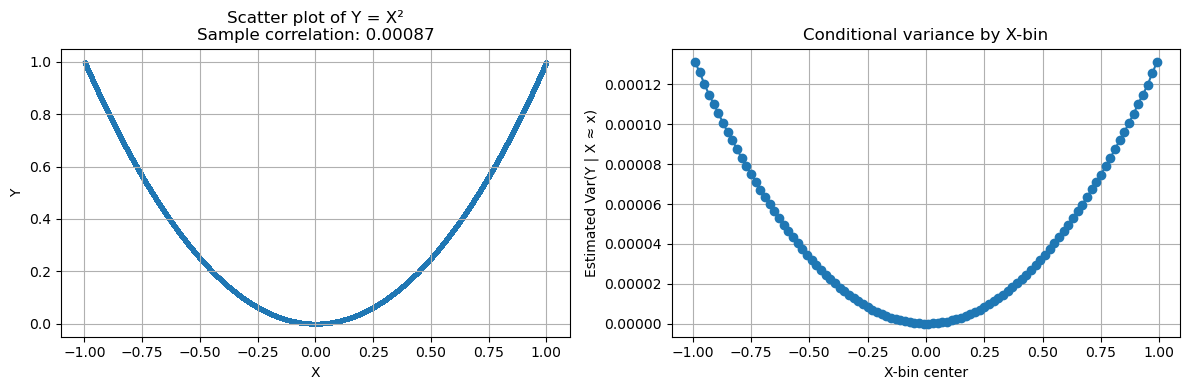

Largest estimated conditional variance with Sample Correlation: 0.0008731522477416733 is 0.00013136281008374416


In [10]:
#use prior Samples of x

#bins: 100 of them
bin_edges = np.linspace(-1,1,101)
bin_centers = (bin_edges[:-1]+bin_edges[1:])/2
conditional_variances = []

#calculate variance of Y within x bin
for left, right in zip(bin_edges[:-1], bin_edges[1:]):
    in_bin = (X >= left) & (X < right)
    Y_in_bin = Y[in_bin]

    variance = np.var(Y_in_bin, ddof = 1)
    conditional_variances.append(variance)

conditional_variances = np.array(conditional_variances)

#2 plots
fig, axes = plt.subplots(1,2,figsize=(12,4))

#scatter plot
axes[0].scatter(X,Y, s=2, alpha=0.2)
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].set_title(
    f"Scatter plot of Y = X²\nSample correlation: {r:.5f}"
)
axes[0].grid(True)

# Est con var
axes[1].plot(bin_centers, conditional_variances, "o-")
axes[1].set_xlabel("X-bin center")
axes[1].set_ylabel("Estimated Var(Y | X ≈ x)")
axes[1].set_title("Conditional variance by X-bin")
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Largest estimated conditional variance with Sample Correlation:", r, "is", 
      np.max(conditional_variances))

We can see the conditional variance for each bin is centered exactly on the curve of the scatter plot. Because variance lies directly on the curve and is miniscule, we can see the relation is deterministic, with every x value corresponding to only one y value.

Sample correlation:              -0.00022
RMSE:                             0.00025
Mean absolute difference:         0.00012
Maximum absolute difference:      0.00205
Total absolute difference:        0.00770


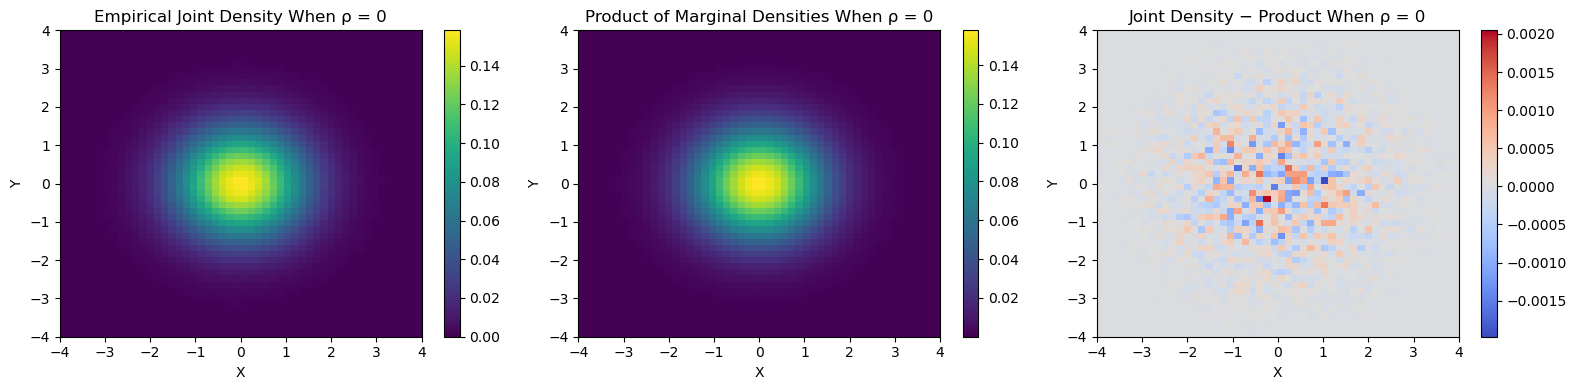

In [11]:
rho = 0.0

# Covariance matrix for two standard normal variables
covariance_matrix = np.array([
    [1.0,  rho],
    [rho, 1.0]
])

samples = rng_step2.multivariate_normal(
    mean=[0, 0],
    cov=covariance_matrix,
    size=n
)

X = samples[:, 0]
Y = samples[:, 1]

#joint density

number_of_bins = 50
bin_edges = np.linspace(-4, 4, number_of_bins + 1)

joint_density, x_edges, y_edges = np.histogram2d(
    X,
    Y,
    bins=[bin_edges, bin_edges],
    density=True
)

#marginal density on their own

density_X, _ = np.histogram(
    X,
    bins=bin_edges,
    density=True
)

density_Y, _ = np.histogram(
    Y,
    bins=bin_edges,
    density=True
)
#mult.  the marginals together

product_of_marginals = np.outer(density_X, density_Y)

#compare the multipled marginals vs actual

difference = joint_density - product_of_marginals

bin_width = bin_edges[1] - bin_edges[0]

rmse = np.sqrt(np.mean(difference**2))
mean_absolute_difference = np.mean(np.abs(difference))
max_absolute_difference = np.max(np.abs(difference))

# Approximate total abs diff across density surface
total_absolute_difference = (
    np.sum(np.abs(difference)) * bin_width**2
)

sample_correlation = np.corrcoef(X, Y)[0, 1]

print(f"Sample correlation:              {sample_correlation:.5f}")
print(f"RMSE:                             {rmse:.5f}")
print(f"Mean absolute difference:         {mean_absolute_difference:.5f}")
print(f"Maximum absolute difference:      {max_absolute_difference:.5f}")
print(f"Total absolute difference:        {total_absolute_difference:.5f}")

# Plot


fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Directly estimated joint density
plot_1 = axes[0].pcolormesh(
    x_edges,
    y_edges,
    joint_density.T,
    shading="auto"
)
axes[0].set_title("Empirical Joint Density When ρ = 0")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
fig.colorbar(plot_1, ax=axes[0])

# Product of marginal densities
plot_2 = axes[1].pcolormesh(
    bin_edges,
    bin_edges,
    product_of_marginals.T,
    shading="auto"
)
axes[1].set_title("Product of Marginal Densities When ρ = 0")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
fig.colorbar(plot_2, ax=axes[1])

# Difference
plot_3 = axes[2].pcolormesh(
    bin_edges,
    bin_edges,
    difference.T,
    shading="auto",
    cmap="coolwarm"
)
axes[2].set_title("Joint Density − Product When ρ = 0")
axes[2].set_xlabel("X")
axes[2].set_ylabel("Y")
fig.colorbar(plot_3, ax=axes[2])

plt.tight_layout()
plt.show()

We can see the Empirical joint density and the product of the marginal densities are closely matched with a root mean square error of 0.00024 between the differences of the two.  This strongly supports the independence of the Gaussian pair as an independent relation would show $$f_{X,Y}(x,y) = f_X(x)f_Y(y)$$ which means the marginal probability multiplied together should be identical to the probability of the joint density.
 
 Because of this, we can see for Gaussian pairs, the depedance is related to the correlation between the pair, unlike our last example. We can say:  $$\text{The jointly Gaussian pair is independant iff the correlation is zero}$$.

 We can also say $$\text{The jointly Gaussian pair is dependant iff the correlation is nonzero}$$
 which I will support with an extra example of this below.

Sample correlation:              0.89992
RMSE:                             0.03585
Mean absolute difference:         0.01597
Maximum absolute difference:      0.20068
Total absolute difference:        1.02180


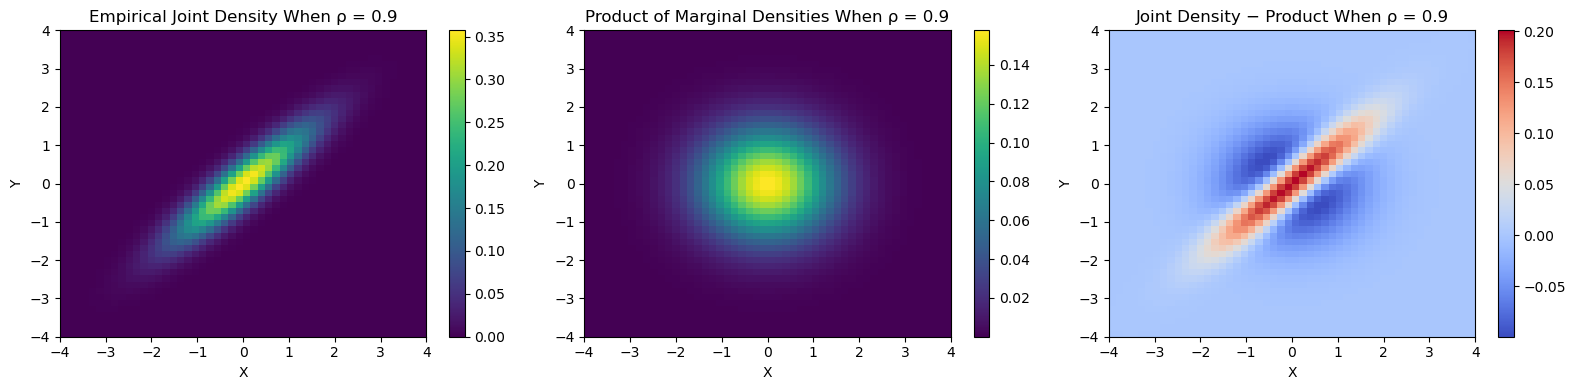

In [12]:
rho = 0.9

# Covariance matrix for two standard normal variables
covariance_matrix = np.array([
    [1.0,  rho],
    [rho, 1.0]
])

samples = rng_step2.multivariate_normal(
    mean=[0, 0],
    cov=covariance_matrix,
    size=n
)

X = samples[:, 0]
Y = samples[:, 1]

#joint density

number_of_bins = 50
bin_edges = np.linspace(-4, 4, number_of_bins + 1)

joint_density, x_edges, y_edges = np.histogram2d(
    X,
    Y,
    bins=[bin_edges, bin_edges],
    density=True
)

#marginal density on their own

density_X, _ = np.histogram(
    X,
    bins=bin_edges,
    density=True
)

density_Y, _ = np.histogram(
    Y,
    bins=bin_edges,
    density=True
)
#mult.  the marginals together

product_of_marginals = np.outer(density_X, density_Y)

#compare the multipled marginals vs actual

difference = joint_density - product_of_marginals

bin_width = bin_edges[1] - bin_edges[0]

rmse = np.sqrt(np.mean(difference**2))
mean_absolute_difference = np.mean(np.abs(difference))
max_absolute_difference = np.max(np.abs(difference))

# Approximate total abs diff across density surface
total_absolute_difference = (
    np.sum(np.abs(difference)) * bin_width**2
)

sample_correlation = np.corrcoef(X, Y)[0, 1]

print(f"Sample correlation:              {sample_correlation:.5f}")
print(f"RMSE:                             {rmse:.5f}")
print(f"Mean absolute difference:         {mean_absolute_difference:.5f}")
print(f"Maximum absolute difference:      {max_absolute_difference:.5f}")
print(f"Total absolute difference:        {total_absolute_difference:.5f}")

# Plot


fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Directly estimated joint density
plot_1 = axes[0].pcolormesh(
    x_edges,
    y_edges,
    joint_density.T,
    shading="auto"
)
axes[0].set_title("Empirical Joint Density When ρ = 0.9")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
fig.colorbar(plot_1, ax=axes[0])

# Product of marginal densities
plot_2 = axes[1].pcolormesh(
    bin_edges,
    bin_edges,
    product_of_marginals.T,
    shading="auto"
)
axes[1].set_title("Product of Marginal Densities When ρ = 0.9")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
fig.colorbar(plot_2, ax=axes[1])

# Difference
plot_3 = axes[2].pcolormesh(
    bin_edges,
    bin_edges,
    difference.T,
    shading="auto",
    cmap="coolwarm"
)
axes[2].set_title("Joint Density − Product When ρ = 0.9")
axes[2].set_xlabel("X")
axes[2].set_ylabel("Y")
fig.colorbar(plot_3, ax=axes[2])

plt.tight_layout()
plt.show()

Simply changing the correlation to be 0.9 from 0, we can see how the product of marginal densities and the empirical joint density are not matching.  From here, we see an example of the earlier statement that $$\text{The jointly Gaussian pair is dependant iff the correlation is nonzero}$$  When we make the correlation nonzero (0.9), we see the RSME becomes 197% larger, indicating a major change in how similar the two are.

 Why would the Gaussian pair's dependance related to correlation when the other dependant relation we looked at was not?  This is because the correlation works on linear relationships.  For the nonlinear relation $Y = X^2$, the variables might be dependant but are not linear.  The Gaussian cloud has a linear tendency because the conditional average is linear, with variables scattering around that average. For the Gaussian pair, $$Cov(X,Y) = \rho \sigma_X \sigma_Y$$  By setting $\rho$ to greater than zero, we see the cloud tilts upward.  When $\rho$ is set to less than zero, we see the cloud tilts down.  When $\rho$ is zero, we see the cloud has no tilt.

 This property makes jointly Gaussian vectors very important in an engineering context, as correlation between them signals dependance.  We can tell if two signals are independant by simply finding their covariance, telling us if there is common noise between them or if the error between the sensors is independant.

## Step 3

For the random vector

$$
\mathbf{X}=
\begin{bmatrix}
X_1 & X_2 & X_3 & X_4
\end{bmatrix}^{T},
$$

the mean vector is

$$
\boldsymbol{\mu}=E[\mathbf{X}].
$$

$$
\Sigma_{ij}
=
\operatorname{Cov}(X_i,X_j)
=
E[(X_i-\mu_i)(X_j-\mu_j)]
=
E[X_iX_j]-\mu_i\mu_j.
$$

Therefore, the covariance matrix is

$$
\Sigma
=
E\left[
(\mathbf{X}-\boldsymbol{\mu})
(\mathbf{X}-\boldsymbol{\mu})^T
\right].
$$

In this step,

$$
\Sigma=
\begin{bmatrix}
4&2&1&0\\
2&5&2&1\\
1&2&3&1\\
0&1&1&2
\end{bmatrix}.
$$

#### 3.1 Check whether the covariance matrix is valid 
A covariance matrix must be symmetric:

$$
\Sigma=\Sigma^T,
$$

and positive semidefinite:

$$
\mathbf{a}^T\Sigma\mathbf{a}\geq 0
$$

for every vector $\mathbf{a}$.

This follows because

$$
\mathbf{a}^T\Sigma\mathbf{a}
=
\operatorname{Var}(\mathbf{a}^T\mathbf{X})
\geq 0.
$$

For a real symmetric matrix, positive semidefiniteness is equivalent to all eigenvalues being nonnegative.

I use `np.linalg.eigh`, which is designed for real symmetric matrices.
I also test the library function on a non-symmetric matrix and a symmetric matrix with a negative eigenvalue. A singular positive semidefinite matrix is still a valid covariance matrix, so we include that case as an additional check.

In [13]:
step3_start = time.perf_counter()

Sigma3 = np.array([
    [4, 2, 1, 0],
    [2, 5, 2, 1],
    [1, 2, 3, 1],
    [0, 1, 1, 2]
], dtype=float)

mu3 = np.zeros(4)
d3 = Sigma3.shape[0]

eigenvalues3, eigenvectors3 = np.linalg.eigh(Sigma3)
determinant3 = np.linalg.det(Sigma3)

nonsymmetric3 = Sigma3.copy()
nonsymmetric3[0, 1] = 3.0

negative3 = np.diag([1.0, 2.0, 3.0, -1.0])
singular3 = np.diag([1.0, 2.0, 3.0, 0.0])

for name3, matrix3, expected3 in [
    ("Project Sigma", Sigma3, True),
    ("Non-symmetric matrix", nonsymmetric3, False),
    ("Negative eigenvalue", negative3, False),
    ("Singular PSD matrix", singular3, True)
]:
    result3 = is_valid_covariance(matrix3)
    print(f"{name3:24s}: {result3} (expected {expected3})")
    assert result3 == expected3

print("\nEigenvalues:", eigenvalues3)
print(f"Determinant: {determinant3:.12f}")
print(
    f"Symmetry residual: "
    f"{np.linalg.norm(Sigma3-Sigma3.T, 'fro'):.3e}"
)
print(f"Smallest eigenvalue: {eigenvalues3[0]:.8f}")
print(
    "All eigenvalues are positive: "
    "Sigma is positive definite, hence PSD."
)

near_psd3 = np.diag([1.0, -5e-11])

assert is_valid_covariance(near_psd3, tol=1e-10)
assert not is_valid_covariance(near_psd3, tol=0.0)

# Check the group library against NumPy's unbiased covariance.
test_data3 = np.array([
    [1., 2.],
    [2., 0.],
    [4., 3.],
    [5., 1.]
])

test_mean3, test_cov3 = sample_mean_cov(test_data3)

mean_difference3 = np.max(
    np.abs(test_mean3-test_data3.mean(axis=0))
)

cov_difference3 = np.max(
    np.abs(
        test_cov3
        - np.cov(test_data3, rowvar=False, ddof=1)
    )
)

print(
    f"Library mean check, max absolute difference: "
    f"{mean_difference3:.3e}"
)

print(
    f"Library covariance check, max absolute difference: "
    f"{cov_difference3:.3e}"
)

np.testing.assert_allclose(
    test_cov3,
    np.cov(test_data3, rowvar=False, ddof=1)
)

Project Sigma           : True (expected True)
Non-symmetric matrix    : False (expected False)
Negative eigenvalue     : False (expected False)
Singular PSD matrix     : True (expected True)

Eigenvalues: [1.264879 1.788195 3.098084 7.848841]
Determinant: 55.000000000000
Symmetry residual: 0.000e+00
Smallest eigenvalue: 1.26487889
All eigenvalues are positive: Sigma is positive definite, hence PSD.
Library mean check, max absolute difference: 0.000e+00
Library covariance check, max absolute difference: 4.441e-16


#### 3.2 Generate samples with the specified covariance

I choose a zero mean because this step specifies the covariance but does not require a particular mean:

$$
\mathbf{X}\sim\mathcal{N}(\mathbf{0},\Sigma).
$$

Each row of the generated data matrix contains one independent four-dimensional observation. Thus, the data matrix has shape
$(N,4)$.

I use the existing `rng_step3` generator. 

#### 3.3 Sample mean and unbiased sample covariance

For $N$ independent observations, the sample mean is

$$
\widehat{\boldsymbol{\mu}}
=
\frac{1}{N}
\sum_{n=1}^{N}\mathbf{x}_n.
$$

The unbiased sample covariance is

$$
\widehat{\Sigma}
=
\frac{1}{N-1}
\sum_{n=1}^{N}
(\mathbf{x}_n-\widehat{\boldsymbol{\mu}})
(\mathbf{x}_n-\widehat{\boldsymbol{\mu}})^T.
$$

I divide by $N-1$ because the mean is estimated from the same data.

The `sample_mean_cov()` library function implements these formulas.

To quantify the estimation error, I use the Frobenius norm:

$$
e_N
=
\|\widehat{\Sigma}-\Sigma\|_F
=
\sqrt{
\sum_{i=1}^{4}\sum_{j=1}^{4}
(\widehat{\Sigma}_{ij}-\Sigma_{ij})^2
}.
$$

I first calculate one estimate at each required sample size.

For independent Gaussian observations, the standard errors are

$$
\operatorname{SE}(\widehat{\mu}_i)
=
\sqrt{\frac{\Sigma_{ii}}{N}},
$$

and

$$
\operatorname{SE}(\widehat{\Sigma}_{ij})
=
\sqrt{
\frac{\Sigma_{ij}^{2}+\Sigma_{ii}\Sigma_{jj}}
{N-1}
}.
$$

These allow me to compare the estimated mean and covariance entries with theoretical values.

In [14]:
N_values3 = np.array([100, 1_000, 10_000, 100_000, 1_000_000])

single_errors3 = np.empty(N_values3.size)
single_means3 = np.empty((N_values3.size, d3))
single_covariances3 = np.empty((N_values3.size, d3, d3))

for j3, N3 in enumerate(N_values3):

# Use the existing Step 3 generator.
    samples3 = rng_step3.multivariate_normal(
        mu3,
        Sigma3,
        size=int(N3),
        method="cholesky"
    )

    mean_hat3, cov_hat3 = sample_mean_cov(samples3)

    single_means3[j3] = mean_hat3
    single_covariances3[j3] = cov_hat3

    single_errors3[j3] = np.linalg.norm(cov_hat3-Sigma3, ord="fro")

# Retain the estimates without keeping every sample array.
    del samples3

print(
    f"{'N':>10} "
    f"{'Single-draw Frobenius error':>30}"
)

for N3, error3 in zip(N_values3, single_errors3):
    print(f"{N3:10d} {error3:30.8f}")

N_last3 = int(N_values3[-1])

mean_se3 = np.sqrt(np.diag(Sigma3)/N_last3)

cov_se3 = np.sqrt((Sigma3**2 + np.outer(np.diag(Sigma3), np.diag(Sigma3))) / (N_last3-1))

print(f"\nAt N = {N_last3:,}:")

print("Estimated mean:", single_means3[-1])
print("Mean minus theory:", single_means3[-1]-mu3)
print("Standard errors of mean components:", mean_se3)
print("\nEstimated covariance:\n", single_covariances3[-1])
print("\nCovariance minus theory:\n", single_covariances3[-1]-Sigma3)
print("\nStandard errors of covariance entries:\n", cov_se3)

         N    Single-draw Frobenius error
       100                     0.95661277
      1000                     0.48011166
     10000                     0.26120002
    100000                     0.05185784
   1000000                     0.02591209

At N = 1,000,000:
Estimated mean: [-0.001777 -0.000017 -0.001675 -0.000002]
Mean minus theory: [-0.001777 -0.000017 -0.001675 -0.000002]
Standard errors of mean components: [0.002    0.002236 0.001732 0.001414]

Estimated covariance:
 [[ 4.00298   1.997402  0.998592 -0.002505]
 [ 1.997402  4.985737  1.990005  0.992835]
 [ 0.998592  1.990005  2.992412  0.994429]
 [-0.002505  0.992835  0.994429  1.997363]]

Covariance minus theory:
 [[ 0.00298  -0.002598 -0.001408 -0.002505]
 [-0.002598 -0.014263 -0.009995 -0.007165]
 [-0.001408 -0.009995 -0.007588 -0.005571]
 [-0.002505 -0.007165 -0.005571 -0.002637]]

Standard errors of covariance entries:
 [[0.005657 0.004899 0.003606 0.002828]
 [0.004899 0.007071 0.004359 0.003317]
 [0.003606 0.004359 

#### 3.4 Repeat the experiment to measure the convergence rate

A single covariance estimate fluctuates randomly. Therefore, a single-draw curve is not reliable enough to fit the convergence rate.

For each sample size $N$, I generate $R$ independent datasets and calculate the error for each dataset:

$$
e_{N,r}
=
\|\widehat{\Sigma}_{N,r}-\Sigma\|_F.
$$

I average the errors themselves:

$$
\overline{e}_N
=
\frac{1}{R}
\sum_{r=1}^{R}e_{N,r}.
$$

This differs from averaging covariance matrices first and then calculating one error.

I use the required repetition counts:

| $N$ | Repetitions $R$ |
|---:|---:|
| $10^2$ | 200 |
| $10^3$ | 200 |
| $10^4$ | 100 |
| $10^5$ | 30 |
| $10^6$ | 10 |

The standard error of the averaged error is

$$
\operatorname{SE}(\overline{e}_N)
=
\frac{s_e}{\sqrt{R}},
$$

where $s_e$ is the sample standard deviation of the errors across repetitions.

The expected convergence rate is

$$
\overline{e}_N\approx C N^{-1/2}.
$$

Taking logarithms gives

$$
\log(\overline{e}_N)
\approx
\log C-\frac{1}{2}\log N.
$$

Therefore, a log-log fit should have slope approximately $-1/2$.

I also calculate

$$
\sqrt{N}\,\overline{e}_N,
$$

which should remain roughly constant if the measured rate is
$N^{-1/2}$.

In [15]:
repetitions3 = np.array([200, 200, 100, 30, 10])

mean_errors3 = np.empty(N_values3.size)
sd_errors3 = np.empty(N_values3.size)
se_errors3 = np.empty(N_values3.size)

all_errors3 = []

for j3, (N3, R3) in enumerate(
    zip(N_values3, repetitions3)
):

    errors3 = np.empty(int(R3))

    for r3 in range(int(R3)):

        samples3 = rng_step3.multivariate_normal(
            mu3,
            Sigma3,
            size=int(N3),
            method="cholesky"
        )

        _, cov_hat3 = sample_mean_cov(samples3)

        errors3[r3] = np.linalg.norm(
            cov_hat3-Sigma3,
            ord="fro"
        )

        del samples3

    all_errors3.append(errors3)

    mean_errors3[j3] = errors3.mean()
    sd_errors3[j3] = errors3.std(ddof=1)

    se_errors3[j3] = (sd_errors3[j3]/np.sqrt(R3))

scaled_errors3 = np.sqrt(N_values3)*mean_errors3
scaled_se3 = np.sqrt(N_values3)*se_errors3

relative_errors3 = (mean_errors3 / np.linalg.norm(Sigma3, ord="fro"))

slope3, log_intercept3 = np.polyfit(
    np.log(N_values3),
    np.log(mean_errors3),
    1
)

fitted_errors3 = (np.exp(log_intercept3) * N_values3**slope3)

print(
    f"{'N':>10} {'R':>5} "
    f"{'Single error':>14} {'Mean error':>14} "
    f"{'SE of mean':>14} {'sqrt(N)*mean':>15} "
    f"{'Scaled SE':>12}"
)

for j3, N3 in enumerate(N_values3):

    print(
        f"{N3:10d} "
        f"{repetitions3[j3]:5d} "
        f"{single_errors3[j3]:14.7f} "
        f"{mean_errors3[j3]:14.7f} "
        f"{se_errors3[j3]:14.7f} "
        f"{scaled_errors3[j3]:15.7f} "
        f"{scaled_se3[j3]:12.7f}"
    )

print(
    f"\nFitted log-log slope: {slope3:.6f}; "
    f"expected: -0.500000"
)

print(
    f"Measured error law: "
    f"approximately N^({slope3:.4f})"
)

print(
    f"Drop per tenfold increase in N, from the fit: "
    f"{10**(-slope3):.4f}"
)

print(
    f"Theoretical drop per decade: "
    f"{np.sqrt(10):.4f}"
)

print(
    f"Scaled-error range: "
    f"{scaled_errors3.min():.4f} "
    f"to {scaled_errors3.max():.4f}"
)

# Approximate handout checks
handout_errors3 = np.array([
    1.56, 0.49, 0.16, 0.046, 0.016
])

print("\nComparison with the handout's approximate averaged errors:")

for N3, measured3, approximate3, se3 in zip(
    N_values3,
    mean_errors3,
    handout_errors3,
    se_errors3
):

    print(
        f"N={N3:7d}: "
        f"measured={measured3:.7f}, "
        f"SE={se3:.7f}, "
        f"handout~{approximate3:.3f}, "
        f"difference={measured3-approximate3:+.7f}"
    )

         N     R   Single error     Mean error     SE of mean    sqrt(N)*mean    Scaled SE
       100   200      0.9566128      1.5427287      0.0369113      15.4272869    0.3691131
      1000   200      0.4801117      0.5083140      0.0126519      16.0743015    0.4000869
     10000   100      0.2612000      0.1499039      0.0054185      14.9903909    0.5418529
    100000    30      0.0518578      0.0530100      0.0032044      16.7632345    1.0133122
   1000000    10      0.0259121      0.0151107      0.0014172      15.1106753    1.4172012

Fitted log-log slope: -0.499979; expected: -0.500000
Measured error law: approximately N^(-0.5000)
Drop per tenfold increase in N, from the fit: 3.1621
Theoretical drop per decade: 3.1623
Scaled-error range: 14.9904 to 16.7632

Comparison with the handout's approximate averaged errors:
N=    100: measured=1.5427287, SE=0.0369113, handout~1.560, difference=-0.0172713
N=   1000: measured=0.5083140, SE=0.0126519, handout~0.490, difference=+0.0183140
N=

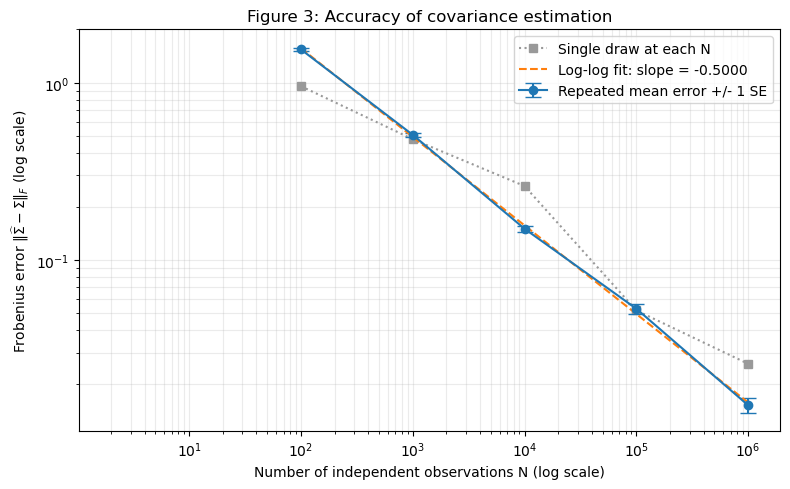

In [16]:
fig3, ax3 = plt.subplots(figsize=(8, 5))

ax3.loglog(
    N_values3,
    single_errors3,
    "s:",
    color="0.6",
    label="Single draw at each N"
)

ax3.errorbar(
    N_values3,
    mean_errors3,
    yerr=se_errors3,
    fmt="o-",
    color="tab:blue",
    capsize=6,
    label="Repeated mean error +/- 1 SE"
)

ax3.loglog(
    N_values3,
    fitted_errors3,
    "--",
    color="tab:orange",
    label=f"Log-log fit: slope = {slope3:.4f}"
)

ax3.set(
    xlabel=(
        "Number of independent observations N "
        "(log scale)"
    ),
    ylabel=(
        r"Frobenius error "
        r"$\|\widehat{\Sigma}-\Sigma\|_F$ "
        r"(log scale)"
    ),
    title="Figure 3: Accuracy of covariance estimation"
)

ax3.grid(True, which="both", alpha=0.25)
ax3.legend()

fig3.tight_layout()
plt.show()

#### Interpretation of Figure 3

The averaged covariance-estimation error decreases approximately as $N^{-1/2}$, as shown by the fitted slope reported in the output and the figure legend.

The printed values of $\sqrt{N}\,\overline{e}_N$ remain roughly constant, providing a second check of this rate. Thus, reducing the error by a factor of two requires approximately four times as many independent observations.

The single-draw curve fluctuates around the averaged curve because each covariance estimate depends on one random dataset. Averaging over independent repetitions makes the convergence trend easier to measure.

The error bars represent one standard error of the averaged Frobenius error. They measure uncertainty in the reported average, rather than the spread of individual covariance estimates.

#### 3.5 Number of covariance parameters

A symmetric $d\times d$ covariance matrix has $d$ diagonal entries and $d(d-1)/2$ distinct off-diagonal entries.

Therefore, the number of free parameters is

$$
p(d)
=
d+\frac{d(d-1)}{2}
=
\frac{d(d+1)}{2}.
$$

For four dimensions,

$$
p(4)=\frac{4(5)}{2}=10.
$$

For one hundred dimensions,

$$
p(100)=\frac{100(101)}{2}=5050.
$$

The number of parameters increases by a factor of

$$
\frac{5050}{10}=505.
$$

As a rough parameter-count planning estimate, assume the squared estimation error scales as $p/N$, with comparable normalization between the two problems. Maintaining the same error then requires the sample size to increase in proportion to $p$:

$$
N_{100}
\approx
10^4\frac{5050}{10}
=
5{,}050{,}000.
$$

This is a heuristic estimate, not a universal requirement for relative Frobenius accuracy.

#### Clarifying the relative-error assumption

Define relative Frobenius error as

$$
\frac{\|\widehat{\Sigma}-\Sigma\|_F}{\|\Sigma\|_F}.
$$

For independent Gaussian observations, the unbiased sample
covariance satisfies

$$
E\left[\|\widehat{\Sigma}-\Sigma\|_F^2\right]
=
\frac{
(\operatorname{tr}\Sigma)^2+\|\Sigma\|_F^2
}{N-1}.
$$

Consequently, the root-mean-square relative error is

$$
\sqrt{
\frac{
1+(\operatorname{tr}\Sigma)^2/\|\Sigma\|_F^2
}{N-1}
}.
$$

Thus, relative accuracy depends on the covariance structure as well as the dimension.

For example, if the 100-dimensional covariance is $I_{100}$, this expression becomes

$$
\sqrt{\frac{101}{N-1}}.
$$

In [17]:
p4_3 = 4*(4+1)//2
p100_3 = 100*(100+1)//2

reference_index3 = int(np.flatnonzero(N_values3 == 10_000)[0])

N_reference3 = int(N_values3[reference_index3])

relative_reference3 = (relative_errors3[reference_index3])

# Rough budget based on the stated parameter-count assumption.
parameter_ratio3 = p100_3/p4_3

N_parameter_budget3 = int(np.ceil(N_reference3*parameter_ratio3))

print(f"Free parameters at d=4: {p4_3}")
print(f"Free parameters at d=100: {p100_3}")

print(
    f"Parameter-count ratio: "
    f"{parameter_ratio3:.1f}"
)

print(
    f"Measured mean relative Frobenius error "
    f"at N={N_reference3:,}: "
    f"{relative_reference3:.6f} "
    f"({100*relative_reference3:.4f}%)"
)

print(
    f"Parameter-count planning heuristic: "
    f"{N_parameter_budget3:,} observations"
)

print("This heuristic assumes squared error scales with parameter count.")
print("The dimension alone does not fix the sample size for relative Frobenius error.")

# Conditional example: a specified 100-D covariance, I_100.
effective_rank3 = (
    np.trace(Sigma3)**2
    / np.linalg.norm(Sigma3, "fro")**2
)

N_identity100_3 = int(
    np.ceil(1 + 101/relative_reference3**2)
)

print(
    f"Effective rank of the 4-D Sigma: "
    f"{effective_rank3:.6f}"
)

print(
    f"For Sigma_100=I_100, matching that error "
    f"as RMS relative error needs about "
    f"{N_identity100_3:,} observations."
)

print("This identity-covariance example and the parameter-count heuristic make different assumptions.")

Free parameters at d=4: 10
Free parameters at d=100: 5050
Parameter-count ratio: 505.0
Measured mean relative Frobenius error at N=10,000: 0.017195 (1.7195%)
Parameter-count planning heuristic: 5,050,000 observations
This heuristic assumes squared error scales with parameter count.
The dimension alone does not fix the sample size for relative Frobenius error.
Effective rank of the 4-D Sigma: 2.578947
For Sigma_100=I_100, matching that error as RMS relative error needs about 341,595 observations.
This identity-covariance example and the parameter-count heuristic make different assumptions.


#### 3.6 Why this matters for a radar array
A radar with 100 array elements must estimate 5050 distinct covariance parameters from a limited number of independent observations, so estimation noise can make interference suppression unreliable.

A designer can use a shrinkage covariance estimator, combining the sample covariance with a structured target to reduce estimation variance when the available data are limited.

## Step 4

Derivation rules for y = Ax + b. 
## Mean Rule: ##
$$\mu_y = \mathbb{E}[y] = \mathbb{E}[Ax + b] = A\mathbb{E}[x] + b = A\mu_x + b$$

## Covariance Rule: ## 
$$\begin{aligned}
\Sigma_y &= \mathbb{E}\left[(y - \mu_y)(y - \mu_y)^T\right] = \mathbb{E}\left[\big(A(x- \mu_x)\big)\big(A(x - \mu_x)\big)^T\right]\\
&= \mathbb{E}\left[A(x- \mu_x)(x - \mu_x)^T A^T\right] \\ 
&= A\,\mathbb{E}\left[(x -\mu_x)(x - \mu_x)^T\right]A^T = A\Sigma_x A^T
\end{aligned}$$

## First Transformation ## 
$A_1 = \begin{bmatrix} 1 & 2 \\ 0 & 1 \\ 1 & -1 \end{bmatrix}$: 
$$ \mu_{y,1} = A_1\mu_x= \begin{bmatrix} 1(1) + 2(-2) \\0(1) + 1(-2) \\ 1(1)- 1(-2) \end{bmatrix} = \begin{bmatrix} -3 \\-2 \\ 3 \end{bmatrix}$$
$$\Sigma_{y,1} = A_1\Sigma_x A_1^T = \begin{bmatrix} 8 & 10 \\ 2 & 4 \\ 2 &-2 \end{bmatrix} \begin{bmatrix} 1 & 0 &1 \\ 2 & 1 & -1\end{bmatrix} = \begin{bmatrix} 28 & 10 & -2 \\ 10 & 4 & -2\\ -2 & -2 & 4 \end{bmatrix}$$

## Rank-Deficient Transformation ## 
$A_2 = \begin{bmatrix} 1 & 1 \\ 2 & 2 \end{bmatrix}$: 
$$\mu_{y,2} = A_2 \mu_x = \begin{bmatrix} -1 \\ -2 \end{bmatrix}. \qquad \Sigma_{y,2} = A_2\Sigma_x A_2^T = \begin{bmatrix} 6 & 6 \\ 12 & 12 \end{bmatrix} \begin{bmatrix} 1 & 2 \\ 1 &2 \end{bmatrix} = \begin{bmatrix} 12 & 24 \\ 24 & 48 \end{bmatrix}$$ 

In [37]:
N = 1000000
mu_x = np.array([1, -2])
Sigma_x = np.array([[4, 2], [2, 4]])

X = rng_step4.multivariate_normal(mu_x, Sigma_x, size = N)
A1 = np.array([[1, 2], [0, 1], [1, -1]])

## exact mean and covariance
mu_y1 = A1 @ mu_x
Sigma_y1 = A1 @ Sigma_x @ A1.T
Y1 = X @ A1.T 
mu_y1_emp, Sigma_y1_emp = sample_mean_cov(Y1)

## standard error from theoretical values
mu_y1_std = np.std(Y1, axis =0, ddof = 1) / np.sqrt(N)
mu_y1_diff = np.abs(mu_y1_emp - mu_y1)
Sigma_y1_frob = np.linalg.norm(Sigma_y1_emp - Sigma_y1, ord='fro') 

print("4.2: First Transformation") 
print("---------------------------")
print(f"Analytical mu_y1: {mu_y1}")
print(f"Empirical mu_y1: {np.round(mu_y1_emp,5)}")
print(f"Absolute Difference: {np.round(mu_y1_diff,5)}")
print(f"Standard Error: {np.round(mu_y1_std,5)}")
print("\nAnalytical Sigma_y1:\n", Sigma_y1)
print("\nEmpirical Sigma:\n", np.round(Sigma_y1_emp, 4))
print(f"\nFrobenius norm || Sigma_emp - Sigma || _F = {Sigma_y1_frob:.5f}")

rank_y1 = np.linalg.matrix_rank(Sigma_y1)
eigen_val = np.linalg.eigvalsh(Sigma_y1)
valid_y1 = is_valid_covariance(Sigma_y1)

print("\n---------------------------")
print("4.3 Rank & Eigenvalues") 
print("---------------------------")
print(f"Rank of Sigma (3x3): {rank_y1}")
print(f"Eigenvalues of Sigma: {[round(float(v), 5) for v in eigen_val]}")
print(f"is_valid_covariance(Sigma): {valid_y1}") 

## rank deficient transformation

A2 = np.array([[1, 1] , [2, 2]])

mu_y2 = A2 @ mu_x
Sigma_y2 = A2 @ Sigma_x @ A2.T 
Y2 = X @ A2.T
mu_y2_emp, Sigma_y2_emp = sample_mean_cov(Y2)
Sigma_y2_frob = np.linalg.norm(Sigma_y2_emp - Sigma_y2, ord='fro') 


rank_y2 = np.linalg.matrix_rank(Sigma_y2)
eigen_val = np.linalg.eigvalsh(Sigma_y2)
valid_y2 = is_valid_covariance(Sigma_y2) 

4.2: First Transformation
---------------------------
Analytical mu_y1: [-3 -2  3]
Empirical mu_y1: [-3.00816 -2.0025   2.99936]
Absolute Difference: [0.00816 0.0025  0.00064]
Standard Error: [0.00529 0.002   0.002  ]

Analytical Sigma_y1:
 [[28 10 -2]
 [10  4 -2]
 [-2 -2  4]]

Empirical Sigma:
 [[28.0165 10.0062 -2.0021]
 [10.0062  4.0036 -2.0045]
 [-2.0021 -2.0045  4.0114]]

Frobenius norm || Sigma_emp - Sigma || _F = 0.02324

---------------------------
4.3 Rank & Eigenvalues
---------------------------
Rank of Sigma (3x3): 2
Eigenvalues of Sigma: [0.0, 4.14359, 31.85641]
is_valid_covariance(Sigma): True


## Part 4.3 Rank of $\Sigma_y$ ## 
Due to the input vector only having 2 random variables, multiplying it by a matrix 3x2 cant create another variable, meaning that samples that are in 3D are forced into a 2D space. Goemetrically this means 3D samples are confined to a flat 2D passing through a mean vector rather than filling a volume.

In [38]:
print("-----------------------------------")
print("4.4: Rank-Deficient Transformation")
print("-----------------------------------")
print(f"Analytical mu_y2: {mu_y2}")
print(f"Empirical mu_y2: {np.round(mu_y2_emp,5)}") 
print("\nAnalytical Sigma_y2:\n", Sigma_y2)
print("\nEmperical Sigma:\n", np.round(Sigma_y2_emp, 5)) 
print(f"Rank of Sigma (2x2): {rank_y2}")
print(f"Eigenvalues of Sigma: {np.round(eigen_val, 5)}")
print(f"is_valid_covariance(Sigma): {valid_y2}") 

-----------------------------------
4.4: Rank-Deficient Transformation
-----------------------------------
Analytical mu_y2: [-1 -2]
Empirical mu_y2: [-1.00565 -2.01131]

Analytical Sigma_y2:
 [[12 24]
 [24 48]]

Emperical Sigma:
 [[12.00764 24.01528]
 [24.01528 48.03057]]
Rank of Sigma (2x2): 1
Eigenvalues of Sigma: [ 0. 60.]
is_valid_covariance(Sigma): True


## Part 4.4: Report $\Sigma_y$ and its rank, describe the set that the output samples lie on ## 
The second row the matrix A is double that of the first row meaning the second coordinate is always equal to twice the first coordinate. This gives the covariance matrix a rank of 1 causing all 2D samples to fall on a single 1D straight line. 

In [39]:
## part 4.5 
det_y2 = np.linalg.det(Sigma_y2)
print("\n----------------------------------------------")
print("Part 4.5 Singular Covariance Breaks Guassian PDF") 
print("----------------------------------------------") 


print(f"np.linalg.det(Sigma_y2) = {det_y2:.4e}")

## call gaussian pdf function from library 
try:
    pdf_val = gaussian_pdf(mu_y2, mu_y2, Sigma_y2)
    print(f"gaussian_pdf returned: {pdf_val}")
except (np.linalg.LinAlgError, ValueError) as err:
    print(f"gaussian_pdf failed as expected ({type(err).__name__}): {err}") 

print("\n The covariance matrix has a determinant of zero, dividing by this will cause the formula to fail.")


----------------------------------------------
Part 4.5 Singular Covariance Breaks Guassian PDF
----------------------------------------------
np.linalg.det(Sigma_y2) = 0.0000e+00
gaussian_pdf failed as expected (ValueError): Sigma must be positive definite.

 The covariance matrix has a determinant of zero, dividing by this will cause the formula to fail.


## Part 4.5 Why the density formula cannot be evaluated? ##
Due to the covariance matrix being non-invertable and having determinant of 0, the desnity formula will fail do to division by zero.

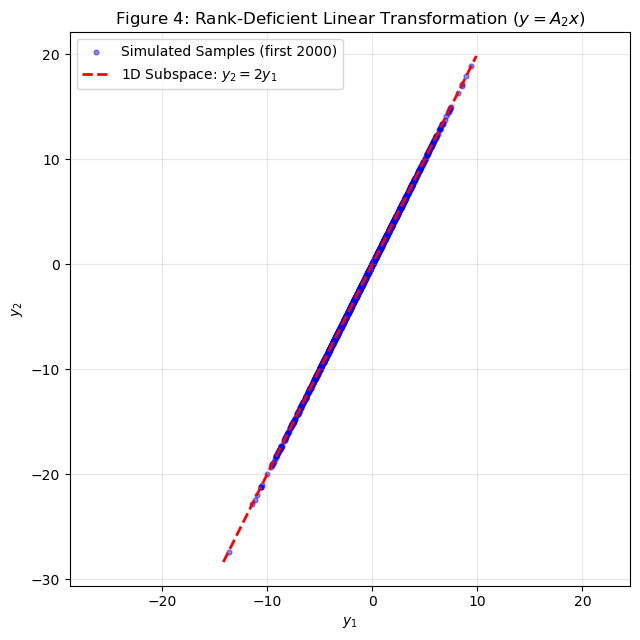

In [40]:
plt.figure(figsize=(6.5, 6.5))
n_plot = 2000
plt.scatter(Y2[:n_plot, 0], Y2[:n_plot, 1], alpha = 0.45, s=12, 
            color = "blue", label=f"Simulated Samples (first {n_plot})")

y1_grid = np.linspace(Y2[:n_plot, 0].min() - .5, Y2[:n_plot, 0].max() + 0.5, 200)
plt.plot(y1_grid, 2.0 * y1_grid, "r--", linewidth = 2, label= "1D Subspace: $y_2 = 2y_1$")

plt.title("Figure 4: Rank-Deficient Linear Transformation ($y = A_2 x$)")
plt.xlabel("$y_1$")
plt.ylabel("$y_2$")
plt.axis("equal")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

## Figure 4 Interpretation ## 
This figure confirms that the rank 1 collapse and all simulated $(y_1, y_2)$ lie right on top of the dashed line with zero spread. This matches the theoretical eigenvalue of a singular covariance matrix $\lambda = 0$

## Step 5

Multivariante Gaussian Density

The d-dimensional Gaussian density:

$\ f_X(x) = \frac{1}{(2\pi)^{d/2}|\Sigma|^{1/2}} \exp\left[-\frac12(x-\mu)^T\Sigma^{-1}(x-\mu)\right] \$


$\ d \$ : Dimension of the random vector, which is 2 here.


$\ x \$ : Point where the density is evaluated


$\ \mu : \text{The mean vector which is } \mu = [0,0]^T \$


$$ \Sigma = \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix} $$ : This is the covariance matrix.


$\ |\Sigma| \$ : Determinant of the covariance matrix which is 12.


$\ \Sigma^{-1} \$ : The inverse of the covariance matrix.


$\ (x-\mu)^T\Sigma^{-1}(x-\mu) \$ : Squared Mahalanobis distance.


$\ \exp \$ : Exponential function


Therefore,

$$ f_X(x) = \frac{1}{2\pi\sqrt{12}} \exp\left[-\frac12(x-\mu)^T \begin{bmatrix} 1/3 & -1/6 \\ -1/6 & 1/3 \end{bmatrix} (x-\mu)\right] $$

In [19]:
#Generate Density and read contours
#Largest Relative difference at 5 scattered points
mu2 = np.zeros(2)
Sigma2 = np.array([[4.,2.],[2.,4.]])
#five scattered points
points = np.array([[0.2,0.4],[-1.0,0.5],[2.0,-1.5],[3.0,2.0],[-2.5,-0.2]])
#Evaluate using Gaussian PDF
ours = gaussian_pdf(points, mu2, Sigma2)
scipy_pdf = stats.multivariate_normal(mean=mu2, cov=Sigma2).pdf(points)
#Calculate relative difference
relative_diff = np.abs(ours-scipy_pdf)/np.maximum(np.abs(scipy_pdf), 1e-15)
#Display results
print("Our PDF:", ours)
print("SciPy PDF:", scipy_pdf)
print("Largest relative difference:", relative_diff.max())

Our PDF: [0.045034 0.034321 0.009833 0.014307 0.017504]
SciPy PDF: [0.045034 0.034321 0.009833 0.014307 0.017504]
Largest relative difference: 8.820802085403093e-16


The largest difference between using Gaussian PDF function and SciPy PDF for 5 random scattered points was 8.821e-16, which is small enough to assume that both PDFs produce similar values. Thus, the multivariante Gaussian PDF was determined by the determinant of the covariance matrix and a linear system that was calculated using a squared Mahalanobis distance. Therefore, since the largest difference was small, we could assume that both implementations agreed with each other. 

To calculate the Largest Relative Difference we used the equation below:

$\ \text{Largest Relative Difference} = \max_i\left( \frac{|f_{\text{ours}}(x_i) f_{\text{SciPy}}(x_i)|} {|f_{\text{SciPy}}(x_i)|} \right) \$

In [20]:
#Confirm that the density integrates to 1 over large region
integral_2d, integral_err = integrate.dblquad(lambda y, x: float(gaussian_pdf(np.array([x,y]), mu2, Sigma2)), -8, 8, lambda x: -8, lambda x: 8)
print(f"Gaussian PDF integral over [-8,8]^2 = {integral_2d:.10f}")
print(f"Quadrature error estimate = {integral_err:.2e}")

Gaussian PDF integral over [-8,8]^2 = 0.9998742891
Quadrature error estimate = 6.12e-11


Since the Gaussian extends infinitely in every direction, the region that we chose was [-8,8] x [-8,8], which is wide relative to the marginal standard deviation of 2 because both variables have a standard deviation of 2. Thus, my region extends 4 standard deviations in both directions from the mean, 0, which makes the tail probability extremely small. As one can see that the integral over the finite region is close to 1 at a value of 0.9998742891, which has a small missing probability that is due to the far tails. In conclusion, we were able to confirm that the Gaussian density is normalized and that there is only a negligible amount of probability outside the selected region.


Figure 5: Gaussian Probability Contours
Contour     Mahalanobis Radius^2   Density Level      Empirical Fraction    Empirical (%)  
-----------------------------------------------------------------------------------------------
50%         1.386294               0.022972           0.5001                50.01%
90%         4.605170               0.004594           0.9001                90.01%
99%         9.210340               0.000459           0.9895                98.95%

Empirical Probability vs. Theoretical Probability
Contour     Theory        Empirical     Difference      Standard Error    Difference/SE  
-------------------------------------------------------------------------------------
50%         0.5000          0.5001          +0.0001            0.00500             0.020
90%         0.9000          0.9001          +0.0001            0.00300             0.033
99%         0.9900          0.9895          -0.0005            0.00099             0.503
Correlation coefficient:
rho

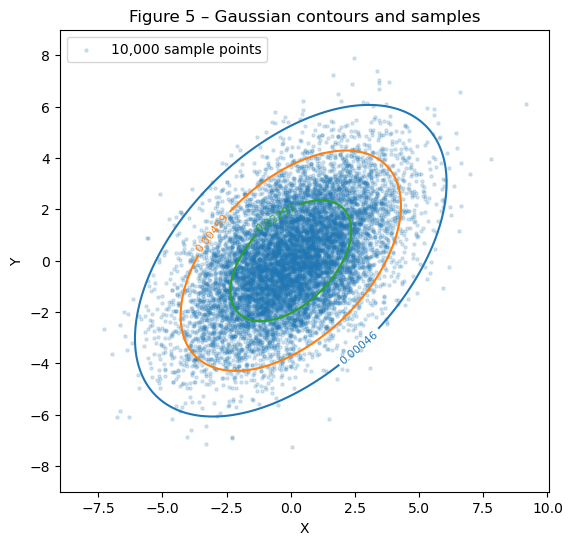

In [21]:
#Plot constant density contours over a scatter with 10^4 samples
N5 = 10_000
s5 = rng_step5.multivariate_normal(mu2, Sigma2, size=N5)
#mark enclosed 50%, 90%, and 99% of probability using chi squared distribution
chi2_levels = stats.chi2.ppf([0.50,0.90,0.99], df=2)
#convert the squared Mahalanobis distance into probability density contour levels
density_levels = np.exp(-0.5*(2*np.log(2*np.pi)+np.linalg.slogdet(Sigma2)[1] +chi2_levels))
invS = np.linalg.solve(Sigma2, np.eye(2))
delta5 = s5-mu2
mahal5 = np.einsum("ni,ij,nj->n", delta5, invS, delta5)
#count the fraction of samples inside
empirical_inside = [(mahal5 <= q).mean() for q in chi2_levels]
contour_percentages = [50, 90, 99]
print("\nFigure 5: Gaussian Probability Contours")
print("=" * 95)
print(f"{'Contour':<12}"
    f"{'Mahalanobis Radius^2':<23}"
    f"{'Density Level':<19}"
    f"{'Empirical Fraction':<22}"
    f"{'Empirical (%)':<15}")
print("-" * 95)
for i, percentage in enumerate(contour_percentages):
    print(f"{percentage}%{'':<9}"
        f"{chi2_levels[i]:<23.6f}"
        f"{density_levels[i]:<19.6f}"
        f"{empirical_inside[i]:<22.4f}"
        f"{empirical_inside[i]*100:.2f}%")
print("=" * 95)

#Standard error comparison
theoretical_inside = np.array([0.50, 0.90, 0.99])
empirical_inside = np.array(empirical_inside)
se_inside = np.sqrt(theoretical_inside * (1 - theoretical_inside) / N5)
differences = empirical_inside - theoretical_inside
difference_in_se = np.abs(differences) / se_inside
print("\nEmpirical Probability vs. Theoretical Probability")
print("=" * 85)
print(f"{'Contour':<12}{'Theory':<14}{'Empirical':<14}"
      f"{'Difference':<16}{'Standard Error':<18}{'Difference/SE':<15}")
print("-" * 85)
for i, percentage in enumerate(contour_percentages):
    print(f"{percentage}%{'':<9}"
        f"{theoretical_inside[i]:.4f}{'':<10}"
        f"{empirical_inside[i]:.4f}{'':<10}"
        f"{differences[i]:+.4f}{'':<12}"
        f"{se_inside[i]:.5f}{'':<13}"
        f"{difference_in_se[i]:.3f}")
print("=" * 85)

#Calculate correlation coefficient
rho = Sigma2[0, 1] / np.sqrt(Sigma2[0, 0] * Sigma2[1, 1])
#Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(Sigma2)
#Sort eigenvalues from largest to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
print("Correlation coefficient:")
print(f"rho = {rho:.4f}")
print("\nEllipse axis information:")
for i in range(2):
    direction = eigenvectors[:, i]
    angle = np.degrees(np.arctan2(direction[1], direction[0]))
    print(f"\nAxis {i+1}:")
    print(f"Eigenvalue = {eigenvalues[i]:.4f}")
    print(f"Eigenvector = {direction}")
    print(f"Direction = {angle:.2f} degrees")
    print(f"One-standard-deviation semiaxis = {np.sqrt(eigenvalues[i]):.4f}")

#Calculate ellipse semiaxis lengths for each contour
print("\nContour ellipse semiaxis lengths:")
for probability, q in zip([50, 90, 99], chi2_levels):
    major = np.sqrt(eigenvalues[0] * q)
    minor = np.sqrt(eigenvalues[1] * q)
    print(f"{probability}% contour:")
    print(f"Major semiaxis = {major:.4f}")
    print(f"Minor semiaxis = {minor:.4f}")

xx = np.linspace(-9,9,240)
yy = np.linspace(-9,9,240)
XX, YY = np.meshgrid(xx, yy)
gridpts = np.column_stack([XX.ravel(), YY.ravel()])
pdf_grid = gaussian_pdf(gridpts, mu2, Sigma2).reshape(XX.shape)
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(s5[:,0], s5[:,1], s=5, alpha=0.18, label="10,000 sample points")
cs = ax.contour(XX, YY, pdf_grid, levels=np.sort(density_levels), colors=["C0","C1","C2"])
ax.clabel(cs, inline=True, fontsize=8)
ax.set(xlabel="X", ylabel="Y", title="Figure 5 – Gaussian contours and samples")
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.show()

The plot of Figure 5 is the Gaussian contours and 10^4 samples with the contours that enclose 50%, 90%, and 99% of the probability. Thus, at 50%, the density level is .02298, which is indicated with the green line, at 90%, the density level is .0046, which is indicated with the orange line, and at 99%, the density level is .00046, which is indicated with the blue line. Therefore, as the contour for the distribution increases, the density level decreases. Although we notice a decrease in the density, as the contour increases, the Mahalanobis radii squared value increases as well. Thus, the Mahalanobis radii squared value is 1.386294 at 50%, 4.605170 at 90%, and 9.210340 at 99%. When verifying the enclosed fractions empirically by counting the samples, we obtain values similar to .5, .9, and .99 with a small standard error of .005 for .5, .003 for .9, and .00099 for .99. Therefore, since the enclosed fractions were similar to the neccessary result, we were able to confirm that the data we recieved for the constant density contour levels was accurate for 10,000 samples in the bivariate Gaussian distribution. To find the contour levels, we used the chi-square distribution with two degrees of freedom because the squared Mahalanobis distance of a bivariate Gaussian random vector follows a chi-square distribution with two degrees of freedom. Afterward, we used the inverse chi-square cumulative distribution function to calculate the Mahalanobis distance thresholds corresponding to 50%, 90%, and 99% probabilities. The thresholds that we obtained were then converted into constant density contour levels using the multivariate Gaussian probability density function. Thus, for two dimensional Gaussian, the Mahalanobis radii squared distance was obtained by using $\ \chi^2_{2}(p) = -2\ln(1-p) \text{ where the contour enclosing probability p is } (x-\mu)^T\Sigma^{-1}(x-\mu) \$. As one can see by the plot above that the contours are ellipses because the covariance matrix stretches the density along different eigenvector directions. In conclusion, since the empirical probabilities were within three standard errors of the theoretical values, we determined that our simulated Guassian 10^4 sample values were accurate.

Derive $\ \rho \text{ and } \Sigma \$

$\ \rho=\frac{\operatorname{Cov}(X,Y)} {\sigma_X\sigma_Y} = \frac{2}{\sqrt{4}\sqrt{4}} = .5 \$

$$ \Sigma = \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix} $$

$\ |\Sigma| = 16 - 4 = 12 \$
<br>
<br>
<br>
Ellipse axes lengths and directions 

Eigenvalues are 6 and 2 where standard deviation semi axis lengths are 

$\ \sqrt6 = 2.449 \text{ and } \sqrt2 = 1.414 \$

$\ \lambda_1 = 6 \qquad \lambda_2 = 2 \$

Eigenvectors are:

$$ v_1=\frac{1}{\sqrt{2}} \begin{bmatrix}1\\1\end{bmatrix} $$

$$ v_2=\frac{1}{\sqrt{2}} \begin{bmatrix}1\\-1\end{bmatrix} $$

Thus, the directions of the ellipse axes are 45 degrees for the major axis with a standard deviation length of 2.449, which is along y = x, and -45 degrees for the minor axis with standard deviation length of 1.414, which is along y = -x. 

The correlation coefficient which was $\ \rho = .5 \$ was calculated from the covariance matrix, which indicates that the two Gaussian random variables have a positive relationship. The eigenvalues of the covariance matrix are 6 and 2, which correspond to the major and minor ellipse axes. Thus, the major axis with a standard deviation length of 2.449 has the direction of 45 degrees, which lies in the y = x, while the minor axis with a standard deviation length of 1.414 has the direction of -45 degrees or 135 degrees, which lies in the y = -x. In conclusion, the ellipse is stretched along the positive diagonal and the semiaxis lengths for the 50%, 90%, and 99% contours were calculated by multiplying the square roots of the eigenvalues by the square root of the corresponding chi-square threshold.

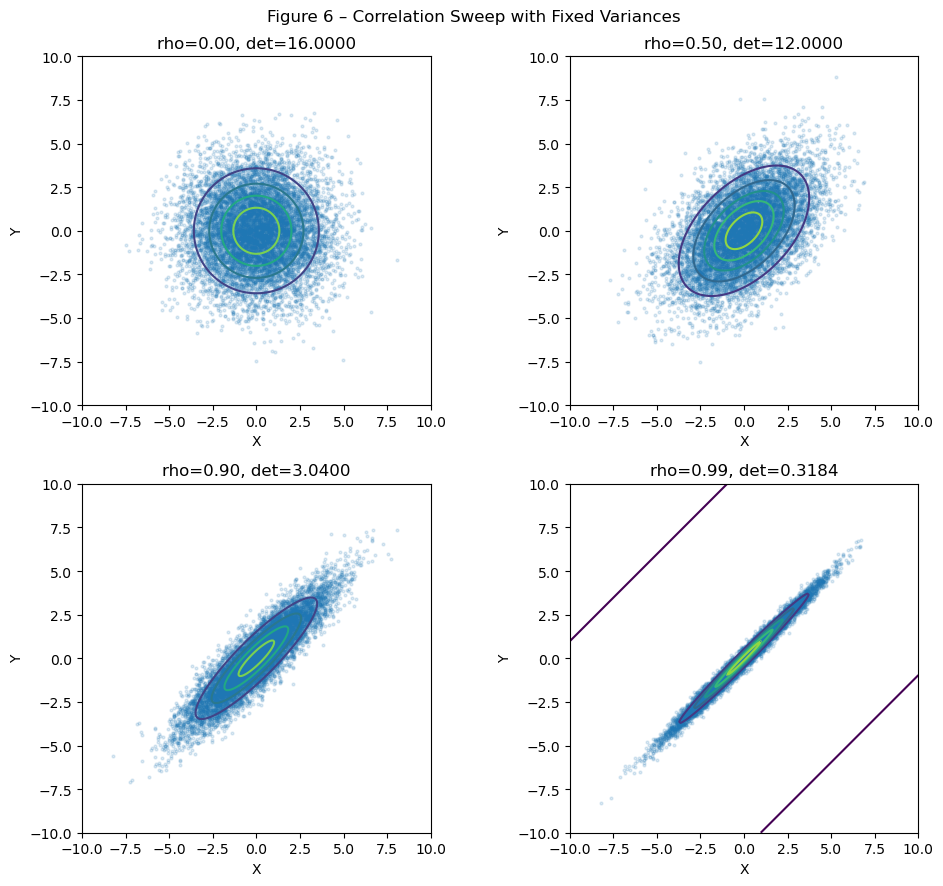

In [22]:
#contour plot for 𝜌 = 0, 𝜌 = 0.5, 𝜌 = 0.9 and 𝜌 = 0.99
#Figure 6: Contour plots for different correlations
rhos = [0.0, 0.5, 0.9, 0.99]
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
u = np.linspace(-10, 10, 240)
U, V = np.meshgrid(u, u)
for ax, rho in zip(axes.ravel(), rhos):
    S = np.array([[4., 4*rho], [4*rho, 4.]])
    #Generate 10,000 samples for each correlation
    sample = rng_step5.multivariate_normal([0, 0], S, size=10_000)
    pgrid = gaussian_pdf(np.column_stack([U.ravel(), V.ravel()]), np.zeros(2), S).reshape(U.shape)
    #Display all 10,000 samples
    ax.scatter(sample[:, 0], sample[:, 1], s=4, alpha=0.15)
    ax.contour(U, V, pgrid, levels=5)
    ax.set_title(f"rho={rho:.2f}, det={np.linalg.det(S):.4f}")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_aspect("equal", adjustable="box")
fig.suptitle("Figure 6 – Correlation Sweep with Fixed Variances")
plt.tight_layout()
plt.show()

In figure 6, one can see that the correlation coefficient increases from 0 to .99, while the Gaussian probability contours become stretched along the positive diagonal and narrow in the perpendicular direction. Thus, the determinant of the covariance matrix decreases from 16 to .3184, which means that it approaches 0 as the correlation coefficient approaches 1. Therefore, this indicates that the two measurements are becoming increasingly dependent and contain more overlapping information. After all, when the correlation coefficient reaches 1, then the covariance matrix becomes singular, which indicates that the second measurement provides no additional independent information other than what was included in the first measurement. In conclusion, since the two measurements are correlated with equal variances and zero means, knowing the first measurement will provide a great indication for the second measurement.

Formula for calculating determinant:

$\ {|\Sigma|=16(1-\rho^2)} \$

$\ |\Sigma|=4(4)-(4\rho)^2 \$

Therefore:
$\ \boxed{|\Sigma|=16(1-\rho^2)} \$

The eigenvalues explain why:
$\ \lambda_1=4(1+\rho),\qquad \lambda_2=4(1-\rho) \$

As $\ \rho \$ approaches 1:
- The major axis becomes longer.
- The minor axis becomes narrower.
- The determinant approaches zero.
- At rho=1, the covariance matrix becomes singular.


## Step 6

We use the same Gaussian random vector and covariance matrix as
Step 5:

$$
\mathbf{X}\sim\mathcal{N}(\mathbf{0},\Sigma),
\qquad
\Sigma=
\begin{bmatrix}
4&2\\
2&4
\end{bmatrix}.
$$

#### 6.1 Eigenvalues and eigenvectors

The eigenvalues satisfy

$$
\det(\Sigma-\lambda I)=0.
$$

Therefore,

$$
\begin{aligned}
\det
\begin{bmatrix}
4-\lambda&2\\
2&4-\lambda
\end{bmatrix}
&=(4-\lambda)^2-4\\
&=\lambda^2-8\lambda+12\\
&=(\lambda-2)(\lambda-6).
\end{aligned}
$$

$$
\lambda_1=2,
\qquad
\lambda_2=6.
$$

Corresponding unit eigenvectors are

$$
\mathbf{v}_1=
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1\\-1
\end{bmatrix},
\qquad
\mathbf{v}_2=
\frac{1}{\sqrt{2}}
\begin{bmatrix}
1\\1
\end{bmatrix}.
$$

The eigendecomposition is

$$
\Sigma=V\Lambda V^T,
$$

where

$$
V=
\begin{bmatrix}
\mathbf{v}_1&\mathbf{v}_2
\end{bmatrix},
\qquad
\Lambda=
\begin{bmatrix}
2&0\\
0&6
\end{bmatrix}.
$$

Because the eigenvectors are orthonormal,

$$
V^TV=VV^T=I.
$$

The short ellipse axis has direction $\mathbf{v}_1$ and one-standard-deviation length $\sqrt{2}$.
The long axis has direction $\mathbf{v}_2$ and one-standard-deviation length $\sqrt{6}$.

An eigenvector and its negative describe the same axis. Therefore, an opposite sign in the numerical eigenvector is valid.

In [23]:
step6_start = time.perf_counter()

# Reuse the covariance, mean, and samples from Step 5.
Sigma6 = np.asarray(Sigma2, dtype=float).copy()
mu6 = np.asarray(mu2, dtype=float).copy()

# Center using the known population mean from Step 5.
X6 = np.asarray(s5, dtype=float) - mu6
N6 = X6.shape[0]
I2_6 = np.eye(2)
np.testing.assert_allclose(Sigma6, [[4., 2.], [2., 4.]])

assert X6.shape == (N6, 2) and N6 > 1
eigenvalues6, V6 = np.linalg.eigh(Sigma6)
Lambda6 = np.diag(eigenvalues6)
print(f"Reused Step 5 sample count: {N6:,}")
print("Eigenvalues, ascending:", eigenvalues6)
print("Eigenvectors, stored as columns:\n", V6)
print("Lambda:\n", Lambda6)

for k6 in range(2): 
    direction6 = V6[:, k6]
    angle6 = np.degrees(np.arctan2(direction6[1], direction6[0]))
    print(
        f"Axis {k6+1}: "
        f"eigenvalue={eigenvalues6[k6]:.6f}, "
        f"sqrt(eigenvalue)="
        f"{np.sqrt(eigenvalues6[k6]):.6f}, "
        f"angle={angle6:.2f} degrees"
    )
print(
    f"Orthogonality residual: "
    f"{np.linalg.norm(V6.T @ V6-I2_6, 'fro'):.3e}"
)
print(
    f"Covariance reconstruction residual: "
    f"{np.linalg.norm(V6 @ Lambda6 @ V6.T-Sigma6, 'fro'):.3e}"
)
np.testing.assert_allclose(V6.T @ V6, I2_6, atol=1e-12)
np.testing.assert_allclose(V6 @ Lambda6 @ V6.T, Sigma6, atol=1e-12)

Reused Step 5 sample count: 10,000
Eigenvalues, ascending: [2. 6.]
Eigenvectors, stored as columns:
 [[-0.707107  0.707107]
 [ 0.707107  0.707107]]
Lambda:
 [[2. 0.]
 [0. 6.]]
Axis 1: eigenvalue=2.000000, sqrt(eigenvalue)=1.414214, angle=135.00 degrees
Axis 2: eigenvalue=6.000000, sqrt(eigenvalue)=2.449490, angle=45.00 degrees
Orthogonality residual: 3.156e-16
Covariance reconstruction residual: 1.295e-15


#### 6.2 Eigenvectors and ellipse axes

The covariance eigenvectors identify the directions of the
Gaussian ellipse axes.

The short axis lies along $x_2=-x_1$ and has
one-standard-deviation length $\sqrt{2}$.

The long axis lies along $x_2=x_1$ and has
one-standard-deviation length $\sqrt{6}$.

The scaled eigenvectors
$\sqrt{\lambda_1}\mathbf{v}_1$ and
$\sqrt{\lambda_2}\mathbf{v}_2$
represent the short and long ellipse axes.

Their alignment with the Step 5 sample cloud will be shown in the combined figure after computing the decorrelated and whitened samples.

#### 6.3 Decorrelation

Define the transformed vector

$$
\mathbf{Y}=V^T(\mathbf{X}-\boldsymbol{\mu}).
$$

Its mean is

$$
E[\mathbf{Y}]
=
V^T(E[\mathbf{X}]-\boldsymbol{\mu})
=
\mathbf{0}.
$$

Using the covariance definition

$$
\begin{aligned}
\operatorname{Cov}(\mathbf{Y})
&=
E\left[
V^T(\mathbf{X}-\boldsymbol{\mu})
(\mathbf{X}-\boldsymbol{\mu})^TV
\right]\\
&=V^T\Sigma V\\
&=V^TV\Lambda V^TV\\
&=\Lambda.
\end{aligned}
$$

Thus,

$$
\operatorname{Cov}(\mathbf{Y})
=
\begin{bmatrix}
2&0\\
0&6
\end{bmatrix}.
$$

The transformed components are uncorrelated, but their variances are still unequal.

#### 6.4 Whitening

Whitening also scales each decorrelated component to unit variance.

Define

$$
W=\Lambda^{-1/2}V^T,
$$

where

$$
\Lambda^{-1/2}
=
\begin{bmatrix}
1/\sqrt{2}&0\\
0&1/\sqrt{6}
\end{bmatrix}.
$$

Let

$$
\mathbf{Z}=W(\mathbf{X}-\boldsymbol{\mu}).
$$

Then

$$
\begin{aligned}
\operatorname{Cov}(\mathbf{Z})
&=W\Sigma W^T\\
&=\Lambda^{-1/2}V^T
  (V\Lambda V^T)
  V\Lambda^{-1/2}\\
&=\Lambda^{-1/2}\Lambda\Lambda^{-1/2}\\
&=I.
\end{aligned}
$$

Our library function `whitening_matrix()` implements this formula.

Each observation is stored as a row in the Python data arrays. Therefore, the transformations are implemented as

`Y6 = X6 @ V6`

and

`Z6 = X6 @ W6.T`.

For finite samples, the estimated covariance will fluctuate around its population value. We report numerical differences and standard errors rather than expecting an exactly diagonal sample covariance.

For independent Gaussian observations,

$$
\operatorname{SE}(\widehat{\Sigma}_{ij})
=
\sqrt{
\frac{\Sigma_{ij}^2+\Sigma_{ii}\Sigma_{jj}}{N-1}
}.
$$

In [24]:
Y6 = X6 @ V6
W6 = whitening_matrix(Sigma6)
Z6 = X6 @ W6.T

print("Whitening matrix from mp3lib:\n", W6)
print("Population covariance after decorrelation:\n", V6.T @ Sigma6 @ V6)
print("Population covariance after whitening:\n", W6 @ Sigma6 @ W6.T)
print(f"Population whitening residual: "
      f"{np.linalg.norm(W6 @ Sigma6 @ W6.T-I2_6, 'fro'):.3e}"
)

np.testing.assert_allclose(V6.T @ Sigma6 @ V6, Lambda6, atol=1e-12)
np.testing.assert_allclose(W6 @ Sigma6 @ W6.T, I2_6, atol=1e-12)
covariances6 = {}
frob_errors6 = {}

for name6, data6, target6 in [
    ("Original", X6, Sigma6),
    ("Decorrelated", Y6, Lambda6),
    ("Whitened", Z6, I2_6)
]:

    mean_hat6, cov_hat6 = sample_mean_cov(data6)
    difference6 = cov_hat6-target6

    # Exact covariance-entry SEs for IID Gaussian observations.
    entry_se6 = np.sqrt((target6**2 + np.outer(np.diag(target6), np.diag(target6))) / (N6-1))
    mean_se6 = np.sqrt(np.diag(target6)/N6)
    error6 = np.linalg.norm(difference6, ord="fro")
    covariances6[name6] = cov_hat6
    frob_errors6[name6] = error6
    
    print(f"\n{name6} samples:")
    print("Estimated mean:", mean_hat6)
    print("Mean minus theory (zero):", mean_hat6)
    print("Standard errors of mean components:", mean_se6)
    print("Estimated covariance:\n", cov_hat6)
    print("Estimated covariance minus theory:\n", difference6)
    print("Standard errors of covariance entries:\n", entry_se6)
    print(
        f"Frobenius covariance error: "
        f"{error6:.8f}"
    )
print(
    f"\nSE of decorrelated off-diagonal covariance: "
    f"{np.sqrt(eigenvalues6.prod()/(N6-1)):.8f}"
)
print(
    f"SE of whitened off-diagonal covariance: "
    f"{1/np.sqrt(N6-1):.8f}"
)
print(
    f"Whitened Gaussian RMS Frobenius-error benchmark: "
    f"{np.sqrt(2*3/(N6-1)):.8f}"
)

Whitening matrix from mp3lib:
 [[-0.5       0.5     ]
 [ 0.288675  0.288675]]
Population covariance after decorrelation:
 [[2. 0.]
 [0. 6.]]
Population covariance after whitening:
 [[1. 0.]
 [0. 1.]]
Population whitening residual: 4.965e-16

Original samples:
Estimated mean: [0.007264 0.023095]
Mean minus theory (zero): [0.007264 0.023095]
Standard errors of mean components: [0.02 0.02]
Estimated covariance:
 [[4.041972 2.008942]
 [2.008942 3.946418]]
Estimated covariance minus theory:
 [[ 0.041972  0.008942]
 [ 0.008942 -0.053582]]
Standard errors of covariance entries:
 [[0.056571 0.044724]
 [0.044724 0.056571]]
Frobenius covariance error: 0.06922876

Decorrelated samples:
Estimated mean: [0.011194 0.021467]
Mean minus theory (zero): [0.011194 0.021467]
Standard errors of mean components: [0.014142 0.024495]
Estimated covariance:
 [[ 1.985253 -0.047777]
 [-0.047777  6.003137]]
Estimated covariance minus theory:
 [[-0.014747 -0.047777]
 [-0.047777  0.003137]]
Standard errors of covari

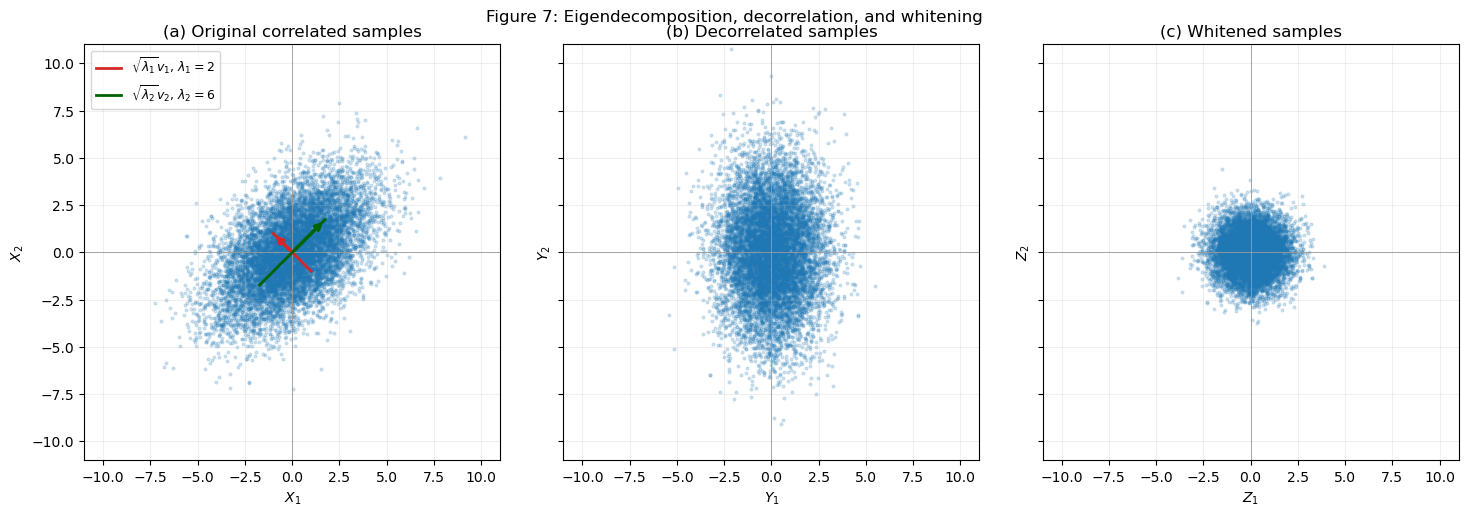

In [25]:
fig7, axes7 = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharex=True,
    sharey=True
)
for ax6, data6, title6, xlabel6, ylabel6 in [
    (axes7[0], X6, "(a) Original correlated samples", r"$X_1$", r"$X_2$"),
    (axes7[1], Y6, "(b) Decorrelated samples", r"$Y_1$", r"$Y_2$"),
    (axes7[2], Z6, "(c) Whitened samples", r"$Z_1$", r"$Z_2$")
]:
    ax6.scatter(data6[:, 0], data6[:, 1], s=4, alpha=0.18)
    ax6.set(title=title6, xlabel=xlabel6, ylabel=ylabel6)
    ax6.axhline(0, color="0.6", linewidth=0.6)
    ax6.axvline(0, color="0.6", linewidth=0.6)
    ax6.grid(alpha=0.2)
    ax6.set_aspect("equal", adjustable="box")

# Draw both ellipse axes.
# Each arrow has length sqrt(lambda).
for k6, color6 in enumerate(["tab:red", "darkgreen"]):
    axis6 = (np.sqrt(eigenvalues6[k6]) * V6[:, k6])
    axes7[0].plot(
        [-axis6[0], axis6[0]],
        [-axis6[1], axis6[1]],
        color=color6,
        linewidth=2,
        label=(
            fr"$\sqrt{{\lambda_{k6+1}}}v_{k6+1}$, "
            fr"$\lambda_{k6+1}={eigenvalues6[k6]:.0f}$"
        )
    )
    axes7[0].annotate(
        "",
        xy=axis6,
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="->",
            color=color6,
            linewidth=2.5
        )
    )

# Identical limits allow the scaling changes to be compared fairly.
limit6 = np.ceil(max(np.abs(X6).max(), np.abs(Y6).max(), np.abs(Z6).max()))
for ax6 in axes7:
    ax6.set_xlim(-limit6, limit6)
    ax6.set_ylim(-limit6, limit6)

axes7[0].legend(loc="upper left", fontsize=9)
fig7.suptitle("Figure 7: Eigendecomposition, decorrelation, and whitening")
fig7.tight_layout()
plt.show()

#### Interpretation of Figure 7
The initial data points form a distribution shaped like a tilted ellipse, as their components exhibit positive covariance. The eigenvectors align with the minor and major axes of this ellipse, with lengths corresponding to the square roots of their associated eigenvalues.

After decorrelation, the ellipse becomes aligned with the coordinate axes. In this state, the variances of the dataset correspond to the eigenvalues; this means the distribution remains more spread out along one specific direction.

Subsequently, through a process known as whitening, all variances are set to one, and the covariances between components become zero. As a result, a dataset following a Gaussian distribution takes on a nearly circular shape.

Sample covariances do not perfectly match theoretical values ​​due to the finite number of observations. The preceding output illustrates these deviations in covariance, the standard errors for each element, and the Frobenius norm of those errors.

Since these observations follow a multivariate Gaussian distribution, the components become statistically independent after decorrelation. However, the whitening process does not guarantee independence for data that does not follow a Gaussian distribution.

#### 6.5 Whitening is not unique

Let $Q$ be an orthogonal matrix, so

$$
QQ^T=I.
$$

If $W$ is a whitening matrix, then

$$
\begin{aligned}
(QW)\Sigma(QW)^T
&=Q(W\Sigma W^T)Q^T\\
&=QIQ^T\\
&=I.
\end{aligned}
$$

Therefore, $QW$ is also a whitening matrix.

We verify this using the rotation matrix

$$
Q=
\begin{bmatrix}
\cos\theta&-\sin\theta\\
\sin\theta&\cos\theta
\end{bmatrix},
\qquad
\theta=\frac{\pi}{6}.
$$

In practice, whitening fixes the covariance but leaves freedom to rotate the whitened coordinate system.

For the same finite dataset, the rotated sample covariance is

$$
\widehat{\Sigma}_{QZ}
=
Q\widehat{\Sigma}_{Z}Q^T.
$$

Because the Frobenius norm is invariant under orthogonal transformations,

$$
\|\widehat{\Sigma}_{QZ}-I\|_F
=
\|\widehat{\Sigma}_{Z}-I\|_F.
$$

As a result, rotation preserves the sample whitening error even though individual covariance entries can change.

In [26]:
theta6 = np.pi/6
Q6 = np.array([
    [np.cos(theta6), -np.sin(theta6)],
    [np.sin(theta6),  np.cos(theta6)]
])

W_rotated6 = Q6 @ W6
Z_rotated6 = X6 @ W_rotated6.T

print("Rotation Q:\n", Q6)
print(
    f"Q orthogonality residual: "
    f"{np.linalg.norm(Q6 @ Q6.T-I2_6, 'fro'):.3e}"
)
print("Population covariance after rotated whitening:\n", W_rotated6 @ Sigma6 @ W_rotated6.T)
print(
    f"Population rotated-whitening residual: "
    f"{np.linalg.norm(W_rotated6 @ Sigma6 @ W_rotated6.T-I2_6, 'fro'):.3e}"
)
_, cov_rotated6 = sample_mean_cov(Z_rotated6)
rotated_se6 = np.sqrt((I2_6**2 + np.ones((2, 2))) / (N6-1))
rotated_error6 = np.linalg.norm(cov_rotated6-I2_6, ord="fro")
print("Estimated rotated-whitened covariance:\n", cov_rotated6)
print("Estimated covariance minus identity:\n", cov_rotated6-I2_6)
print("Standard errors of covariance entries:\n", rotated_se6)
print(
    f"Original whitening sample error: "
    f"{frob_errors6['Whitened']:.8f}"
)
print(
    f"Rotated whitening sample error: "
    f"{rotated_error6:.8f}"
)
np.testing.assert_allclose(Q6 @ Q6.T, I2_6, atol=1e-12)
np.testing.assert_allclose(W_rotated6 @ Sigma6 @ W_rotated6.T, I2_6, atol=1e-12)
np.testing.assert_allclose(cov_rotated6, Q6 @ covariances6["Whitened"] @ Q6.T, atol=1e-12)
np.testing.assert_allclose(rotated_error6, frob_errors6["Whitened"], atol=1e-12)

Rotation Q:
 [[ 0.866025 -0.5     ]
 [ 0.5       0.866025]]
Q orthogonality residual: 1.052e-17
Population covariance after rotated whitening:
 [[ 1. -0.]
 [-0.  1.]]
Population rotated-whitening residual: 6.475e-16
Estimated rotated-whitened covariance:
 [[ 1.006545 -0.010315]
 [-0.010315  0.986604]]
Estimated covariance minus identity:
 [[ 0.006545 -0.010315]
 [-0.010315 -0.013396]]
Standard errors of covariance entries:
 [[0.014143 0.010001]
 [0.010001 0.014143]]
Original whitening sample error: 0.02085872
Rotated whitening sample error: 0.02085872


#### 6.6 Whitening the four-dimensional covariance from Step 3

We now apply the same library function to

$$
\Sigma_4=
\begin{bmatrix}
4&2&1&0\\
2&5&2&1\\
1&2&3&1\\
0&1&1&2
\end{bmatrix}.
$$

Its eigendecomposition gives

$$
\Sigma_4=V_4\Lambda_4V_4^T.
$$

Define

$$
W_4=\Lambda_4^{-1/2}V_4^T.
$$

The same calculation gives

$$
W_4\Sigma_4W_4^T=I_4.
$$

We first verify this matrix identity numerically. Next, generate one million independent four-dimensional Gaussian observations using the existing Step 6 generator, apply $W_4$, and estimate the resulting covariance.

The sample covariance should approach $I_4$, with its remaining differences explained by sampling variability. We report the Frobenius error and the standard errors of individual entries.

In [27]:
# The same 4-D covariance used in Step 3.
Sigma4_6 = np.array([
    [4, 2, 1, 0],
    [2, 5, 2, 1],
    [1, 2, 3, 1],
    [0, 1, 1, 2]
], dtype=float)
I4_6 = np.eye(4)
W4_6 = whitening_matrix(Sigma4_6)
population_white4_6 = (W4_6 @ Sigma4_6 @ W4_6.T)
print("4-D whitening matrix:\n", W4_6)
print("4-D population whitened covariance:\n", population_white4_6)
print(
    f"4-D population whitening residual: "
    f"{np.linalg.norm(population_white4_6-I4_6, 'fro'):.3e}"
)
np.testing.assert_allclose(population_white4_6, I4_6, atol=1e-12)
N4_6 = 1_000_000
samples4_6 = rng_step6.multivariate_normal(np.zeros(4), Sigma4_6, size=N4_6, method="cholesky")
whitened4_6 = samples4_6 @ W4_6.T
mean_white4_6, cov_white4_6 = sample_mean_cov(whitened4_6)
entry_se4_6 = np.sqrt((I4_6**2 + np.ones((4, 4))) / (N4_6-1))
error_white4_6 = np.linalg.norm(cov_white4_6-I4_6, ord="fro")
print(
    f"\n4-D Monte Carlo sample count: "
    f"{N4_6:,}"
)
print("Estimated whitened mean:", mean_white4_6)
print("Mean minus theory (zero):", mean_white4_6)
print("SE of each mean component:", np.full(4, 1/np.sqrt(N4_6)))
print("Estimated whitened covariance:\n", cov_white4_6)
print("Estimated covariance minus identity:\n", cov_white4_6-I4_6)
print("Standard errors of covariance entries:\n", entry_se4_6)
print(
    f"4-D sample whitening Frobenius error: "
    f"{error_white4_6:.8f}"
)
print(
    f"4-D Gaussian RMS Frobenius-error benchmark: "
    f"{np.sqrt(4*5/(N4_6-1)):.8f}"
)
del samples4_6, whitened4_6

4-D whitening matrix:
 [[ 0.210351 -0.048082 -0.479171  0.717234]
 [-0.245148  0.499819 -0.457418 -0.200188]
 [-0.438421  0.091099  0.213221  0.277137]
 [-0.175256 -0.25854  -0.157452 -0.071124]]
4-D population whitened covariance:
 [[ 1. -0. -0.  0.]
 [-0.  1. -0.  0.]
 [-0. -0.  1.  0.]
 [ 0.  0.  0.  1.]]
4-D population whitening residual: 1.318e-15

4-D Monte Carlo sample count: 1,000,000
Estimated whitened mean: [-0.001547  0.001061 -0.000317 -0.000515]
Mean minus theory (zero): [-0.001547  0.001061 -0.000317 -0.000515]
SE of each mean component: [0.001 0.001 0.001 0.001]
Estimated whitened covariance:
 [[ 0.998988 -0.001162  0.001904  0.001954]
 [-0.001162  1.003579  0.00009  -0.000944]
 [ 0.001904  0.00009   0.998562  0.000081]
 [ 0.001954 -0.000944  0.000081  0.997247]]
Estimated covariance minus identity:
 [[-0.001012 -0.001162  0.001904  0.001954]
 [-0.001162  0.003579  0.00009  -0.000944]
 [ 0.001904  0.00009  -0.001438  0.000081]
 [ 0.001954 -0.000944  0.000081 -0.002753]]


## Step 7: The Conditional Gaussian

Conditional Density of $Y$ given $X = x$ 

Let $(X, Y)$ be jointly Gaussian with mean $\mu_ = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$ and covariance $\Sigma = \begin{bmatrix} 4 & 2 \\ 2 & 4 \end{bmatrix}$ 

Conditional density is defined by $$f_{Y/X}(\mid x) = \frac{f_{X,Y}(x, y)}{f_X(x)}$$ 

##  Part 7.1: Conditional Mean ## 
$\mu_{Y/X=x} = \rho\frac{\sigma_Y}{\sigma_X}x = (0.5)\frac{2}{2}x = 0.5x$ 

##  Part 7.1: Conditional Variance ## 
$\sigma_{Y|X=x}^2 = \sigma_Y^2(1-\rho^2) = 4(1-0.5^2) = 3$ 

##  Part 7.2: General Partitioned Gaussian Vector ## 
$\begin{bmatrix} Y \\ X \end{bmatrix} \sim \mathcal{N}\left(\begin{bmatrix} \mu_Y \\ \mu_X\end{bmatrix}, \begin{bmatrix} \Sigma_{YY} & \Sigma_{YX} \\ \Sigma_{XY} & \Sigma_{XX} \end{bmatrix}\right)$, the conditional distribution $Y$ given $X=x$ is Gaussian with: 
$$\mu_{Y|X=x} = \mu_Y + \Sigma_{YX} \Sigma_{XX}^{-1}(x- \mu_X)$$ 
$$\Sigma_{Y|X=x} = \Sigma_{YY} - \Sigma_{YX}\Sigma_{XX}^{-1}\Sigma_{XY}$$ 

##  Part 7.2: Special Case ## 
$mu_X = 0$, $\mu_Y = 0$, $\Sigma_{XX} = 4$, $\Sigma_{YY} = 4$, and $\Sigma_{YX} = \Sigma_{XY} = 2$
$$\mu_{Y|X=x} = 0 + 2(4)^{-1}(x-0) = 0.5x, \qquad \Sigma_{Y/X=x} = 4 -2(4)^{1}(2) = 4-1 = 3$$

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 
from mp3lib import sample_mean_cov, is_valid_covariance

SEED = 1506714529 
rng = np.random.default_rng(SEED) 
rng_step7 = rng.spawn(1)[0]

N = 1000000
mu = np.array([0, 0])
sigma = np.array([[4, 2], [2, 4]]) 

## verify validity using library functions 
print("\n-----------------------")
print("STEP 7: Conditional Gaussian")
print("-----------------------") 
print(f"is_valid_covariance(sigma): {is_valid_covariance(sigma)}")

samples = rng_step7.multivariate_normal(mu, sigma, size = N) 
## check empirical mean and covariance using library 
mu_emp, sigma_emp = sample_mean_cov(samples) 
print(f"Empirical mean: {np.round(mu_emp, 5)}")
print(f" Joint covariance Frobenius error: {np.linalg.norm(sigma_emp - sigma, ord = 'fro'):.5f}")

X = samples[:, 0]
Y = samples[:, 1] 
## create bins 
bin_edges = np.linspace(-5, 5, 41)
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

valid_centers = []
cond_mean = []
cond_mean_std = []
cond_var = []

for i in range(len(bin_edges) - 1):
    in_bin = ( X >= bin_edges[i]) & (X < bin_edges[i+1])
    count = np.sum(in_bin)

    if count >= 50: 
        y_bin = Y[in_bin]
        valid_centers.append(bin_centers[i])
        cond_mean.append(np.mean(y_bin))
        cond_var.append(np.var(y_bin, ddof=1))
        cond_mean_std.append(np.std(y_bin, ddof=1) / np.sqrt(count))

valid_centers= np.array(valid_centers)
cond_mean = np.array(cond_mean)
cond_var = np.array(cond_var)
cond_mean_std = np.array(cond_mean_std) 

(slope, intercept), cov_fit = np.polyfit(valid_centers, cond_mean, deg= 1, cov = True)
slope_std = np.sqrt(cov_fit[0,0])
slope_diff = abs(slope - .5)

##compare conditional var over theortical
mean_cond_var= np.mean(cond_var)
var_diff = abs(mean_cond_var - 3)
var_std = np.std(cond_var, ddof=1) / np.sqrt(len(cond_var)) 

print("\n----------------------")
print("7.3: Binned Conditional Mean")
print("----------------------") 
print(f"Analytical Slope:  0.5000")
print(f"Fitted empirical slope: {slope:.5f} \u00b1 {slope_std:.5f}")
print(f"Absolute Difference: {slope_diff:.5f} ({slope_diff / slope_std:.2f} standard errors)")
print(f"Fitted Intercept: {intercept:.5f} (Theory: 0.0000)") 

print("\n----------------------")
print("7.4: Binned Conditional Variance")
print("----------------------") 
print (f"Analytical variance: 3.0000")
print(f"Mean binned variance: {mean_cond_var:.5f} \u00b1 {var_std:.5f}")
print(f"Absolute Difference: {var_diff:.5f}")


## Part 7.4 ## 
We can show analytically and empirically the variance of the gaussian Y, given X=x, does not depend on x. Given the equation $\sigma_{Y|X=x}^2 = \sigma_Y^2(1-\rho^2)$ we can see that x is not on the right side. When holding X=x to the same constant we can treat Y as the variable, where in other distributions shape changes with the conditioning value, making this a special case. 

## Part 7.5 ## 
For the jointly gaussian vector, conditioning a variable yields another gaussian whose mean is linear. Since MMSE is already linear it makes it optimal over a nonlinear estimator, not just convenient.

In [ ]:
fig, axes = plt.subplots(1,2, figsize = (12,5))

## panel 1 
axes[0].errorbar(valid_centers, cond_mean, yerr = cond_mean_std, fmt="o",
                 color="blue", markersize = 5, capsize = 3, label ="Binned empirical mean")
axes[0].plot(valid_centers, 0.5 * valid_centers, "r-", linewidth = 2,
        label = "Analytical: $E[Y|X=x] = 0.5x$")
axes[0].set_title("Figure 8a: Conditional Mean $E[Y|X=x]$")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("E[Y|X=x]$")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

## panel 2 
axes[1].scatter(valid_centers, cond_var, color="green", s=30,
                 label ="Binned empirical mean")
axes[1].axhline(3, color="r", linestyle = "-", linewidth= 2,
                label = "Analytical $Variance(Y|X=x) = 3$")
axes[1].set_ylim(0,5)
axes[1].set_title("Figure 8b: Conditional Variance $Variance(Y|X=x)$")
axes[1].set_xlabel("$x$")
axes[1].set_ylabel("$Var(Y|X=x)$")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Figure 8 Interpretation ## 
Figure 8a shows binned empirical means lying directly on the analytical line that is equal to 0.5 with a slope of 0.50017. Matching the theoretical slope within 0.20 standard errors. Figure 8b shows empirical conditional variances flat along a horizontal line of analyitcal variance equal to 3. This confirms visually that Y does not depend on X. 

## Step 8

The quantity $\ S \sim N(0,4) \$ is measured by two sensors: 

$\ X_1 = S + N_1,\qquad X_2 = S + N_2 \$

The Noise vector is zero mean: 

$\ N = \mathbf1=[N_1,N_2]^T \$

where:

$$ \Sigma_N = \begin{bmatrix} 1&c \\ c&2 \end{bmatrix} $$

Sensor 2 is also noiser than sensor 1, while the c parameter controls how correlated the noise is.

Derivation for $\ \Sigma_{xx} \text{ and } \Sigma_{sx} \text{ in terms of } \sigma_S^2 \text{ and } \Sigma_N \$ :

$\ \mathbf x = [X_1,X_2]^T \text{ therefore, } \mathbf1 = 11^T \text{ and } \sigma_S^2 = 4 \$


After all, $\ \mathbf x = \mathbf1S + \mathbf N \$


$\ \Sigma_{xx} = E[\mathbf x\mathbf x^T] \$

$\ E[\mathbf x\mathbf x^T] = \sigma_S^2 [1,1] + \Sigma_N \$

$\ \sigma_S^2 [1,1] + \Sigma_N = 4 + \Sigma_N \$

= $$ \Sigma_N = \begin{bmatrix} 1 + 4 & c + 4 \\ c + 4 & 2 + 4 \end{bmatrix} $$

= $$ \begin{bmatrix} 5 & 4+c \\ 4+c & 6 \end{bmatrix} $$

$\ \Sigma_{xx} = \$ 

$$ \begin{bmatrix} 5 & 4+c \\ 4+c & 6 \end{bmatrix} $$

$\ \Sigma_{sx}=E[S\mathbf x^T] = \sigma_S^2[1,1] = 4[1,1] = [4,4] \$

The linear MMSE estimator $$ \hat S = \mathbf w^T \mathbf x \text{ has } \mathbf w = \Sigma_{xx}^{-1} \Sigma_{xs} $$ to minimize the mean square error. 

The resulting MMSE is:

$$ \operatorname{MMSE} = \sigma_S^2 - \Sigma_{sx} \Sigma_{xx}^{-1} \Sigma_{xs} $$

$$ E[S]=0,\qquad \sigma_S^2=\operatorname{Var}(S)=4 $$

The optimal weight vector is calculated using

$$ \mathbf w = \Sigma_{XX}^{-1} \Sigma_{XS} $$

$$ \Sigma_{XS} = \Sigma_{SX}^T $$

$$ \mathbf w = \begin{bmatrix} 5 & 4+c \\ 4+c & 6 \end{bmatrix}^{-1} \begin{bmatrix} 4 \ 4 \end{bmatrix} $$

$$ \mathbf w= \frac{1}{30-(4+c)^2} \begin{bmatrix} 6 & -(4+c)\\ -(4+c) & 5 \end{bmatrix} \begin{bmatrix} 4 \\ 4 \end{bmatrix} $$

Thus, the two optimal weights are

$$ {w_1 = \frac{4(2-c)}{30-(4+c)^2}} $$

$$ {w_2=\frac{4(1-c)}{30-(4+c)^2}} $$

when c=1 $$ {w_2=\frac{4(1-c)}{30-(4+c)^2}} $$ is equal to 0 and negative beyond 1.

$$ \hat S = w_1X_1 + w_2X_2 $$
<br>
<br>
<br>
The minimum mean-square error is

$$ \sigma_S^2 - \Sigma_{SX} \Sigma_{XX}^{-1} \Sigma_{XS} $$

Substitute the known values:

$$ \text{MMSE} = 4 - \begin{bmatrix} 4 & 4 \end{bmatrix} \begin{bmatrix} 5 & 4+c \\ 4+c & 6 \end{bmatrix}^{-1} \begin{bmatrix} 4 \\ 4 \end{bmatrix} $$

$\ \operatorname{MMSE}(c) = \frac{4(2-c^2)}{14-8c-c^2} \$


The noise covariance is Positive Semi-Definite when the diagonal entries are non-negative and the determinant is non-negative. Thus, Σ𝑁 is a valid covariance when it is PSD.

Thus,

$\ 2-c^2 \geq 0 \$

$$ |c|\leq\sqrt2 $$

It is positive definite when:

$$|c| < \sqrt2 $$

In conclusion, Σ𝑁 is valid when $$|c| < \sqrt2 = .41421 $$ and at the endpoints it is also singular.

when $$|c| < \sqrt1 $$

$\ \operatorname{MMSE}(1) = \frac{4(2-1^2)}{14-8c-1^2} = 4/5 \$

Thus, since the diagonal entries are non negative and the determinant is non-negative, Σ𝑁 is a valid covariance matrix.


In [35]:
#Tabulate 𝑤1, 𝑤2 and the MMSE at different c values
sigma_s2 = 4.0
def step8_matrices(c):
    SigmaN = np.array([[1.,c],[c,2.]])
    one = np.ones(2)
    Sxx = sigma_s2*np.outer(one,one)+SigmaN
    Ssx = sigma_s2*one
    return SigmaN,Sxx,Ssx
def step8_theory(c):
    _,Sxx,Ssx=step8_matrices(c)
    w=lmmse_weights(Sxx,Ssx)
    mse=sigma_s2-Ssx@w
    return w,mse
c_values=np.array([-1.4,-1.0,-0.5,0.0,0.5,1.0,1.2,1.4])
best_single= sigma_s2*1/(sigma_s2+1) #sensor 1 noise variance is 1
table=[]
for cval in c_values:
    w,mse=step8_theory(cval)
    equal_mse=(3+2*cval)/4
    table.append((cval,w[0],w[1],mse,best_single,equal_mse))
print("c       w1        w2        MMSE       sensor1-only   equal weights")
for row in table:
    print(f"{row[0]:5.1f}  {row[1]:8.5f}  {row[2]:8.5f}  {row[3]:9.6f}  " f"{row[4]:9.6f}      {row[5]:9.6f}")

c       w1        w2        MMSE       sensor1-only   equal weights
 -1.4   0.58520   0.41308   0.006885   0.800000       0.050000
 -1.0   0.57143   0.38095   0.190476   0.800000       0.250000
 -0.5   0.56338   0.33803   0.394366   0.800000       0.500000
  0.0   0.57143   0.28571   0.571429   0.800000       0.750000
  0.5   0.61538   0.20513   0.717949   0.800000       1.000000
  1.0   0.80000   0.00000   0.800000   0.800000       1.250000
  1.2   1.08108  -0.27027   0.756757   0.800000       1.350000
  1.4   2.85714  -1.90476   0.190476   0.800000       1.450000


After comparing each result against the best single sensor and naive equal weighting we noticed that the best single sensor appears at c = 1, because the best single sensor produces a result of .8, which appears throughout the chart.

At c = 1, the estimator ignores sensor 2 and uses only sensor 1, that produces a value of .8. Thus, the denominator 14 - 8c - c^2 is positive throughout the interval, which produces a value of 1-c is equal to the sign of w2. Therefore, when c<1 w2>0, when c=1 w2=1, and when c>1 w2<0.

$$ {w_2=\frac{4(1-c)}{30-(4+c)^2}} $$

c=1:

$$ {w_2=\frac{4(1-1)}{30-(4+1)^2}} $$

$$ w_2 = 0 $$

$$ {w_1 = \frac{4(2-c)}{30-(4+c)^2}} $$

$$ {w_1 = \frac{4(2-1)}{30-(4+1)^2}} $$

$$ {w_1 = \frac{4}{30-(5)^2}} $$

$$ {w_1 = \frac{4}{5}} $$

$$ w_1 = .8 $$

$\ \operatorname{MMSE}(c) = \frac{4(2-c^2)}{14-8c-c^2} \$

$\ \operatorname{MMSE}(1) = \frac{4(2-1^2)}{14-8(1)-1^2} \$

$\ \operatorname{MMSE}(1) = \frac{4}{14-8-1} \$

$\ \operatorname{MMSE}(1) = \frac{4}{5} \$

$\ \operatorname{MMSE}(1) = .8 \$


Proof of stationary point:

$\ \frac{d}{dc}\operatorname{MMSE}(c) = \frac{32(c-2)(c-1)}{(c^2+8c-14)^2} \$

Thus, when c=1 is stationary because the derivative of MMSE is 0 at c=1. Since the second derivative is -32/25 at c = 1, which is less than 0, the stationary point is a local max not a min. After all, the other root of c = 2 is outside the admissible range.

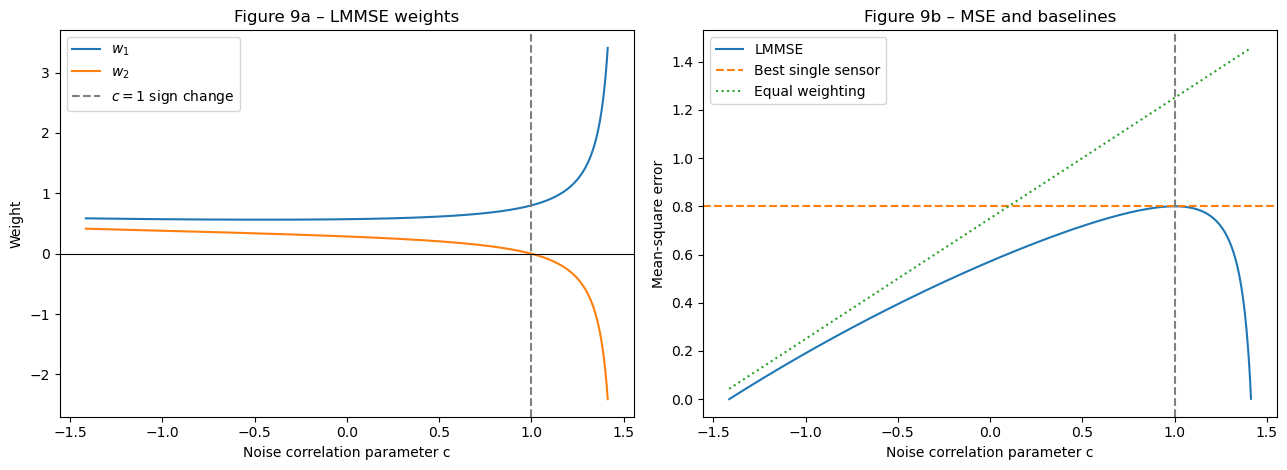

In [36]:
#plot figure 9 for different c values
cplot=np.linspace(-np.sqrt(2)+1e-4,np.sqrt(2)-1e-4,600)
weights_plot=np.array([step8_theory(cv)[0] for cv in cplot])
mse_plot=np.array([step8_theory(cv)[1] for cv in cplot])
equal_plot=(3+2*cplot)/4
fig,ax=plt.subplots(1,2,figsize=(13,4.8))
ax[0].plot(cplot,weights_plot[:,0],label="$w_1$")
ax[0].plot(cplot,weights_plot[:,1],label="$w_2$")
ax[0].axhline(0,color="black",linewidth=.8)
ax[0].axvline(1,color="gray",linestyle="--",label="$c=1$ sign change")
ax[0].set(xlabel="Noise correlation parameter c",ylabel="Weight", title="Figure 9a – LMMSE weights")
ax[0].legend()
ax[1].plot(cplot,mse_plot,label="LMMSE")
ax[1].axhline(best_single,color="C1",linestyle="--",label="Best single sensor")
ax[1].plot(cplot,equal_plot,color="C2",linestyle=":",label="Equal weighting")
ax[1].axvline(1,color="gray",linestyle="--")
ax[1].set(xlabel="Noise correlation parameter c",ylabel="Mean-square error", title="Figure 9b – MSE and baselines")
ax[1].legend()
plt.tight_layout()
plt.show()

When C > 1, the weight on the second cell becomes negative.  It might seem counterintuitive to subtract away this noise as we are removing the signal we are trying to guess.  However, it becomes much more beneficial to do so as noise rises as the nose becomes increasingly positively correlated with sensor 1's noise as c increases.  Because Sensor 2 is noiser than sensor 1, an increase in correlation between the two is capturing a lot of that noise.  When we subtract that out, we remove a lot of the noise both sensors are detecting.

By subtracting $X_1$ from $X_2$, we see the noise from each subtracts:
$$X_1 - X_2 = (S+N_1)-(S+N_2) = N_1 - N_2$$

Then,
$$Var(X_1 - X_2) = Var(N_1 - N_2)$$

Because $$Var(N_1-N_2) = Var(N_1) - Var(N_2) - 2Cov(N_1,N_2)$$

we can say $Var(N_1) = 1$, $Var(N_2) = 2$ and $Cov(N_1,N_2) = c$ from the earlier noise covariance matrix.

From there, we plug our values in to get $Var(X_1 - X_2) = 1+2 - 2c = 3-2c$.  As c increases, our varience of $X_1 - X_2$ decreases

Using our closed form MMSE formula from earlier, we can find MMSE at multiple points:
$MMSE(c) = \frac{4(2-c^2)}{14-8c-c^2}$


When c = 0, the MMSE is $MMSE(c) = \frac{4(2)}{14} = 0.5714$

When c = 1.4, the MMSE is $MMSE(c) = \frac{4(2-1.4^2)}{14-8*1.4-1.4^2} = 0.1904$

The reason why MMSE improves by 100% is the same reason why the variance shrinks: the stronger noise correlation shrinks the varience of the noise difference, making it easier to remove from the signal as correlation rises.  When c = 1.4, the variance  of the noise difference is only 0.2.  As we identify the noise, it becomes much easier to cancel.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

sigma_s_squared = 4 #this is varience, given
c_values = np.linspace(-np.sqrt(2), np.sqrt(2), 500)
mmse_values = []

w1_values = []
w2_values = []


def calculate_mmse(c):
    
    Sigma_N = np.array([  #our array with noise weights.  c is covarience shared between signals.  
        [1, c],
        [c, 2]
    ])

    Sigma_XX = sigma_s_squared * np.ones((2, 2)) + Sigma_N #finding the between X1 and X2
    
    Sigma_sX = sigma_s_squared * np.ones((1, 2)) #signal vs x (no noise here)

    #weights for lmmse
    weights = lmmse_weights(Sigma_XX, Sigma_sX.T)

    mmse = (
        sigma_s_squared
        - Sigma_sX @ np.linalg.solve(Sigma_XX, Sigma_sX.T)
    ).item()

    return float(mmse), weights.ravel() # makes weights 1d array

    

for c in c_values:
    mmse, weights = calculate_mmse(c)
    mmse_values.append(mmse)
    w1_values.append(weights[0])
    w2_values.append(weights[1])
    
w1_values = np.array(w1_values)
w2_values = np.array(w2_values)
mmse_values = np.array(mmse_values)

#plotting stuff

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(c_values, w1_values, label=r"$w_1$")
axes[0].plot(c_values, w2_values, label=r"$w_2$")
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].axvline(1, color="red", linestyle="--", label="c = 1")
axes[0].set_xlabel("Noise correlation parameter c")
axes[0].set_ylabel("Optimal weight")
axes[0].set_title("Optimal sensor weights versus c")
axes[0].grid(True)
axes[0].legend()




axes[1].plot(c_values, mmse_values, label="MMSE(c)")

# Mark a few important locations
axes[1].axvline(0, color="gray", linestyle="--", label="c = 0")
axes[1].axvline(1, color="red", linestyle="--", label="c = 1")

axes[1].set_xlabel("Noise correlation parameter c")
axes[1].set_ylabel("MMSE")
axes[1].set_title("MMSE versus noise correlation")
axes[1].grid(True)
axes[1].legend()
fig.suptitle("Figure 9", fontsize=16)
plt.tight_layout()
plt.show()


The MMSE increases up to c = 1 where it hits its maxima, then sharply decreases.  At c=1, we get the worst estimate for all accepted values of c.  As c approaches either endpoint, the MMSE approaches zero as the noise becomes closely correlated or opposing in a way that lets it be cancelled.  On the subplot to the left, we can see the noises are closely anticorrelated when they are more negative, and so they are weighted similarly to cancel.  On the right, the noises are strongly correlated, which is why w1 is weighted positive while w2 is weighted heavily negative to cancel out the noise.

In [ ]:
def monte_carlo_mse(c, n_trials=1_000_000, seed=12345):

    analytic_mmse, weights = calculate_mmse(c)
    S = rng_step8.normal(
        loc=0,
        scale=np.sqrt(sigma_s_squared),
        size=n_trials
    )

    # Generate cor noise 
    Sigma_N = np.array([
        [1, c],
        [c, 2]
    ])

    N = rng_step8.multivariate_normal(
        mean=[0, 0],
        cov=Sigma_N,
        size=n_trials
    )
    N1 = N[:, 0]
    N2 = N[:, 1]

    # Gen sensor measurements
    X1 = S + N1
    X2 = S + N2

    # Put the sensor meas in rows:
    # row k = [X1_k, X2_k]
    X = np.column_stack((X1, X2))

    # LMMSE
    S_hat = X @ weights

    # errors
    squared_errors = (S - S_hat)**2

    # Simulated MSE
    simulated_mse = np.mean(squared_errors)

    # standard error
    mse_standard_error = (
        np.std(squared_errors, ddof=1)
        / np.sqrt(n_trials)
    )

    return (
        analytic_mmse,
        simulated_mse,
        mse_standard_error,
        weights
    )

for c in [0.8, 1.4]:
    analytic, simulated, se, weights = monte_carlo_mse(c)

    print(f"c = {c}")
    print(f"  weights:             {weights}")
    print(f"  analytic MMSE:       {analytic:.8f}")
    print(f"  simulated MSE:       {simulated:.8f}")
    print(f"  MSE standard error:  {se:.8f}")
    print(f"  absolute difference: {abs(simulated - analytic):.8f}")
    print()

The analytic MSE and simulated MSE are close for both c = 0.8 and c = 1.4 with standard errors of 0.00110 and 0.00026 for each, respectively.  This shows the Monte Carlo simulation matches our theoretical values rather closely for both values.

Given the choice between two sensors with independent noise and two with highly correlated noise, as a systems engineer, I would specify the two sensors with independent noise because they provide more independent information and produce a more reliable estimate of the signal. Thus, highly correlated noise can reduce the benefit of having a second sensor because both sensors can experience errors at the same time. Therefore, if highly correlated sensors were considered, a systems engineer would need to know the noise covariance and the correlation coefficient, which includes the magnitude and sign. After all, to exploit the correlation, one might need to know the LMMSE estimator to improve the estimate or the comparison of the resulting MMSE for both sensor configurations before they make a final decision. In conclusion, a systems engineer needs to determine whether the correlation is stable over time so that they can calculate the noise covariance matrix and determine whether using both sensors improves the signal.

## Bonus A

Let

$$
\mathbf{Z}\sim\mathcal{N}(\mathbf{0},I),
$$

so its components are independent standard Gaussian random variables.

#### Cholesky construction

For a positive-definite covariance matrix, the Cholesky
factorization gives

$$
\Sigma=LL^T.
$$

Define

$$
\mathbf{X}=\boldsymbol{\mu}+L\mathbf{Z}.
$$

The mean is

$$
E[\mathbf{X}]
=
\boldsymbol{\mu}+LE[\mathbf{Z}]
=
\boldsymbol{\mu}.
$$

Its covariance is

$$
\operatorname{Cov}(\mathbf{X})
=
L\operatorname{Cov}(\mathbf{Z})L^T
=
LIL^T
=
LL^T
=
\Sigma.
$$

#### Eigendecomposition construction

For a symmetric positive-semidefinite covariance matrix,

$$
\Sigma=V\Lambda V^T.
$$

Define

$$
A=V\Lambda^{1/2},
\qquad
\mathbf{X}=\boldsymbol{\mu}+A\mathbf{Z}.
$$

Then

$$
\operatorname{Cov}(\mathbf{X})
=
AA^T
=
V\Lambda^{1/2}\Lambda^{1/2}V^T
=
V\Lambda V^T
=
\Sigma.
$$

I verify both methods on the two-dimensional covariance from Step 5 and the four-dimensional covariance from Step 3.

Only `standard_normal()` is used to generate the random inputs because observations are stored as rows; the transformation is implemented as `normals @ factor.T + mean`.

The two methods share the same standard-normal inputs within each dimension. Their factors differ, so their finite-sample covariance estimates can differ even though both have the correct population covariance.

In [28]:
bonusA_start = time.perf_counter()
N_A = 1_000_000
Sigma2_A = np.array([
    [4., 2.],
    [2., 4.]
])
Sigma4_A = np.array([
    [4, 2, 1, 0],
    [2, 5, 2, 1],
    [1, 2, 3, 1],
    [0, 1, 1, 2]
], dtype=float)
scatterA = {}
errorsA = {}
for caseA, SigmaA in [
    ("2-D", Sigma2_A),
    ("4-D", Sigma4_A)
]:
    dA = SigmaA.shape[0]
    muA = np.zeros(dA)
    
    # The only random sampler used for these vectors.
    normalsA = rng_bonusA.standard_normal((N_A, dA))
    print(f"\n{caseA}: N={N_A:,}")
    for methodA in ["cholesky", "eigh"]:
        factorA = covariance_factor(SigmaA, method=methodA)
        samplesA = normalsA @ factorA.T + muA
        meanA, covarianceA = sample_mean_cov(samplesA)
        differenceA = covarianceA - SigmaA

        # Gaussian covariance-entry standard errors.
        se_covA = np.sqrt((SigmaA**2 + np.outer(np.diag(SigmaA), np.diag(SigmaA))) / (N_A - 1))
        errorA = np.linalg.norm(differenceA, ord="fro")
        errorsA[(caseA, methodA)] = errorA
        print(f"\nMethod: {methodA}")
        print(
            f"Factor reconstruction error: "
            f"{np.linalg.norm(factorA @ factorA.T-SigmaA, 'fro'):.3e}"
        )
        print("Sample mean minus theory:", meanA - muA)
        print("Mean component SEs:", np.sqrt(np.diag(SigmaA)/N_A))
        print("Estimated covariance:\n", covarianceA)
        print("Covariance minus theory:\n", differenceA)
        print("Covariance entry SEs:\n", se_covA)
        print(
            f"Frobenius covariance error: "
            f"{errorA:.8f}"
        )
        if dA == 2:
            scatterA[methodA] = (samplesA[:10_000].copy())
        np.testing.assert_allclose(factorA @ factorA.T, SigmaA, atol=1e-12)
        del samplesA
    del normalsA


2-D: N=1,000,000

Method: cholesky
Factor reconstruction error: 4.441e-16
Sample mean minus theory: [0.004525 0.001791]
Mean component SEs: [0.002 0.002]
Estimated covariance:
 [[4.007037 2.005015]
 [2.005015 4.001487]]
Covariance minus theory:
 [[0.007037 0.005015]
 [0.005015 0.001487]]
Covariance entry SEs:
 [[0.005657 0.004472]
 [0.004472 0.005657]]
Frobenius covariance error: 0.01010154

Method: eigh
Factor reconstruction error: 2.453e-15
Sample mean minus theory: [-0.002734  0.001791]
Mean component SEs: [0.002 0.002]
Estimated covariance:
 [[3.998493 1.996471]
 [1.996471 4.001487]]
Covariance minus theory:
 [[-0.001507 -0.003529]
 [-0.003529  0.001487]]
Covariance entry SEs:
 [[0.005657 0.004472]
 [0.004472 0.005657]]
Frobenius covariance error: 0.00542055

4-D: N=1,000,000

Method: cholesky
Factor reconstruction error: 0.000e+00
Sample mean minus theory: [-0.00017  -0.002632 -0.002491 -0.001338]
Mean component SEs: [0.002    0.002236 0.001732 0.001414]
Estimated covariance:
 [[

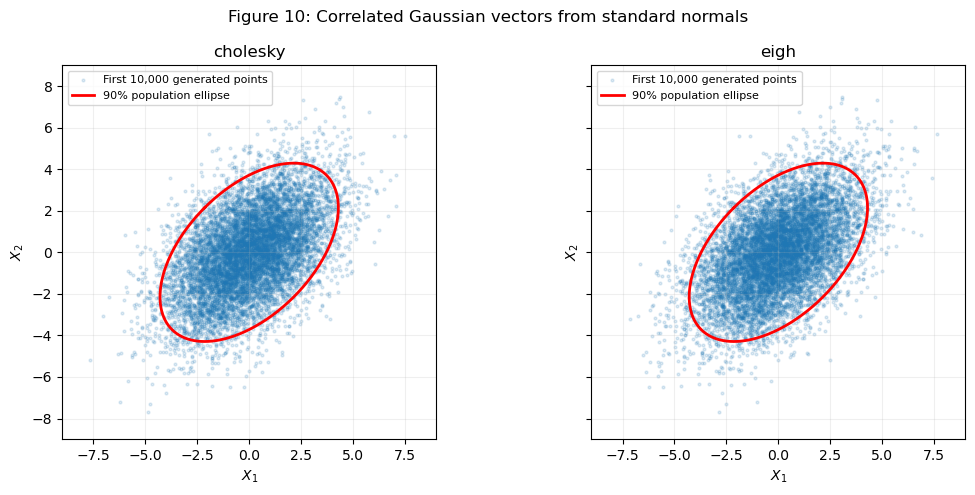

In [29]:
angleA = np.linspace(0, 2*np.pi, 400)
circleA = np.column_stack([np.cos(angleA), np.sin(angleA)])
ellipseA = (np.sqrt(-2*np.log(1-0.90)) * circleA @ covariance_factor(Sigma2_A, "eigh").T)
fig10, axes10 = plt.subplots(
    1, 2,
    figsize=(11, 5),
    sharex=True,
    sharey=True
)
for axA, methodA in zip(axes10, ["cholesky", "eigh"]):
    shownA = scatterA[methodA]
    axA.scatter(
        shownA[:, 0],
        shownA[:, 1],
        s=4,
        alpha=0.15,
        label="First 10,000 generated points"
    )
    axA.plot(
        ellipseA[:, 0],
        ellipseA[:, 1],
        "r-",
        lw=2,
        label="90% population ellipse"
    )
    axA.set(
        title=methodA,
        xlabel=r"$X_1$",
        ylabel=r"$X_2$"
    )
    axA.set_aspect(
        "equal",
        adjustable="box"
    )
    axA.set_xlim(-9, 9)
    axA.set_ylim(-9, 9)
    axA.grid(alpha=0.2)
    axA.legend(fontsize=8)
fig10.suptitle("Figure 10: Correlated Gaussian vectors from standard normals")
fig10.tight_layout()
plt.show()

#### Interpretation of Figure 10

Both construction methods produce sets of points with an elliptical distribution, where the orientation and dispersion are determined by a target covariance matrix.
The aforementioned discrepancies regarding covariance and standard error indicate how well these results align with that target.

For the sake of readability, only the initial portion of each generated dataset is displayed in the plots; however, all generated observations are used to estimate the covariance.

#### Which method is cheaper?

For a positive-definite covariance matrix, the Cholesky method is generally less computationally expensive, as it only requires determining a single triangular factor rather than finding the complete set of eigenvalues and eigenvectors.

Both decomposition methods exhibit a computational complexity that grows cubically with the dimension of the matrix; however, the Cholesky method typically involves a smaller constant factor. Once the factor has been obtained, both approaches described below generate samples through matrix multiplication.

The performance evaluation procedure separates the factor-construction phase from the random-sampling phase. The reported results represent the median values obtained from five distinct timing measurements, with each measurement consisting of ten repetitions of the decomposition process.
#### What happens for a singular covariance?

Consider

$$
\Sigma_{\mathrm{singular}}
=
\begin{bmatrix}
1&1\\
1&1
\end{bmatrix}.
$$

Its eigenvalues are zero and two, so it is positive semidefinite but not positive definite.

The standard Cholesky algorithm requires positive definiteness and encounters a zero pivot, so NumPy raises an error.

The eigendecomposition construction still works because the square root of a zero eigenvalue is defined. The generated Gaussian is degenerate: its samples lie on the line $X_1=X_2$.

In [30]:
from timeit import repeat

# Measure factor construction, including the same input checks.
for d_benchA in [4, 64]:
    indexA = np.arange(d_benchA)
    benchmarkA = (0.7**np.abs(indexA[:, None] - indexA[None, :]))
    benchmarkA += 0.1*np.eye(d_benchA)
    timesA = {}
    for methodA in ["cholesky", "eigh"]:
        measurementsA = repeat(
            lambda: covariance_factor(benchmarkA, method=methodA), number=10, repeat=5)
        timesA[methodA] = (np.median(measurementsA)/10)
    print(
        f"d={d_benchA}: median time per factor, "
        f"Cholesky="
        f"{1e6*timesA['cholesky']:.2f} microseconds, "
        f"eigh="
        f"{1e6*timesA['eigh']:.2f} microseconds"
    )

singularA = np.array([
    [1.0, 0.0],
    [0.0, 0.0]
])

print("\nSingular covariance is valid PSD:", is_valid_covariance(singularA))
print("Eigenvalues:", np.linalg.eigh(singularA)[0])
print("Determinant:", np.linalg.det(singularA))

# Call NumPy directly to demonstrate Cholesky's behavior.
try:
    L_singularA = np.linalg.cholesky(singularA)

except np.linalg.LinAlgError as exc:
    print("Expected Cholesky failure:", exc)

else:
    print("Cholesky returned:\n", L_singularA)
    print("The matrix is still singular; returning a factor does not establish positive definiteness.")

# The eigenvalue construction supports zero eigenvalues.
factor_singularA = covariance_factor(singularA, method="eigh")
degenerateA = (rng_bonusA.standard_normal((10_000, 2))  @ factor_singularA.T)
print(
    f"Eigen-factor reconstruction error: "
    f"{np.linalg.norm(factor_singularA @ factor_singularA.T-singularA, 'fro'):.3e}"
)
print(
    f"Maximum absolute second coordinate: "
    f"{np.max(np.abs(degenerateA[:, 1])):.3e}"
)

d=4: median time per factor, Cholesky=128.13 microseconds, eigh=161.20 microseconds
d=64: median time per factor, Cholesky=269.64 microseconds, eigh=1554.50 microseconds

Singular covariance is valid PSD: True
Eigenvalues: [0. 1.]
Determinant: 0.0
Expected Cholesky failure: Matrix is not positive definite
Eigen-factor reconstruction error: 0.000e+00
Maximum absolute second coordinate: 0.000e+00


#### Cholesky on a singular covariance matrix

I tested

$$
\Sigma=
\begin{bmatrix}
1&0\\
0&0
\end{bmatrix},
$$

which has eigenvalues zero and one and determinant zero. Therefore, it is positive semidefinite but not positive definite.

The standard Cholesky routine requires positive definiteness. The zero eigenvalue produces a zero pivot, violating this requirement. In our environment, the routine returned "nan" (not a number) values instead of raising an exception; these nonfinite values indicate
numerical failure and cannot be used as a valid factor.

The eigendecomposition method still works because zero eigenvalues have well-defined square roots. Its factor reconstructs the covariance, and the generated samples lie on $X_2=0$.

## Bonus B

#### Dataset and source
I use the historical stock-price dataset `Stocks.csv` bundled with Matplotlib. Its file header credits Yahoo Finance.

Source example: https://matplotlib.org/stable/gallery/showcase/stock_prices.html

The four selected numeric columns are:
- IBM
- AAPL: Apple
- MSFT: Microsoft
- ADBE: Adobe

Each retained row contains an observation with all four selected prices present. Rows with missing values in any selected column are removed.

#### PCA from the sample covariance

Let $X$ contain observations as rows. First, subtract the sample
mean of each column:

$$
X_c=X-\widehat{\boldsymbol{\mu}}.
$$

The sample covariance matrix is

$$
\widehat{\Sigma}
=
\frac{X_c^TX_c}{N-1}.
$$

We eigendecompose it:

$$
\widehat{\Sigma}=V\Lambda V^T.
$$

For PCA, the eigenvalues are sorted in descending order:

$$
\lambda_1\geq\lambda_2\geq\cdots\geq\lambda_d.
$$

The principal-component scores are

$$
T=X_cV.
$$

The fraction of variance explained by component $k$ is

$$
r_k=
\frac{\lambda_k}
{\sum_{j=1}^{d}\lambda_j}.
$$

Therefore, the first two components capture

$$
r_1+r_2
=
\frac{\lambda_1+\lambda_2}
{\sum_{j=1}^{d}\lambda_j}.
$$

#### Standardized analysis

Repeating the calculation after dividing each centered column by its sample standard deviation:

$$
Z_{nj}
=
\frac{X_{nj}-\widehat{\mu}_j}
{\widehat{\sigma}_j}.
$$

Each standardized column has a sample variance of one. Its covariance matrix is the sample correlation matrix.

In [31]:
bonusB_start = time.perf_counter()
data_pathB = get_sample_data("Stocks.csv", asfileobj=False)
tableB = np.genfromtxt(
    data_pathB,
    delimiter=",",
    names=True,
    skip_header=1,
    dtype=None,
    encoding="utf-8"
)

featuresB = [
    "IBM",
    "AAPL",
    "MSFT",
    "ADBE"
]

all_dataB = np.column_stack([tableB[nameB] for nameB in featuresB])
completeB = np.isfinite(all_dataB).all(axis=1)
dataB = all_dataB[completeB]
datesB = tableB["Date"][completeB]
print("Source: Matplotlib's bundled Stocks.csv; its header credits Yahoo Finance.")
print("Source example: https://matplotlib.org/stable/gallery/showcase/stock_prices.html")
print("Selected columns:", featuresB)
print(
    f"Original rows: {len(all_dataB)}; "
    f"removed incomplete rows: "
    f"{(~completeB).sum()}"
)
print(
    f"Retained data shape: "
    f"{dataB.shape}"
)
print(
    f"Retained date range: "
    f"{datesB[0]} to {datesB[-1]}"
)
print("Sample column standard deviations:", dataB.std(axis=0, ddof=1))

Source: Matplotlib's bundled Stocks.csv; its header credits Yahoo Finance.
Source example: https://matplotlib.org/stable/gallery/showcase/stock_prices.html
Selected columns: ['IBM', 'AAPL', 'MSFT', 'ADBE']
Original rows: 524; removed incomplete rows: 133
Retained data shape: (391, 4)
Retained date range: 1990-01-01 to 2022-06-28
Sample column standard deviations: [ 42.291056  35.814997  66.67351  135.665626]


In [32]:
rawB = pca_analysis(dataB, standardize=False)
standardizedB = pca_analysis(dataB, standardize=True)
for labelB, resultB in [("Original columns", rawB), ("Standardized columns", standardizedB)]:
    print(f"\n{labelB}")
    print("Estimated covariance:\n", resultB["covariance"])
    print("Eigenvalues, descending:", resultB["eigenvalues"])
    print("Eigenvectors, stored as columns:\n", resultB["eigenvectors"])
    print("Explained variance fractions:", resultB["explained"])
    print(
        f"First two PCs together: "
        f"{100*resultB['explained'][:2].sum():.6f}%"
    )
    _, score_covB = sample_mean_cov(
        resultB["scores"]
    )
    target_covB = np.diag(
        resultB["eigenvalues"]
    )
    print(
        f"Score covariance minus diagonal eigenvalues, "
        f"Frobenius norm: "
        f"{np.linalg.norm(score_covB-target_covB, 'fro'):.3e}"
    )
    print(
        f"Total eigenvalue sum minus covariance trace: "
        f"{abs(resultB['eigenvalues'].sum()-np.trace(resultB['covariance'])):.3e}"
    )
    print("PC1 eigenvector coefficients:")

    for nameB, coefficientB in zip(featuresB, resultB["eigenvectors"][:, 0]):
        print(
            f"  {nameB:5s}: "
            f"{coefficientB:+.6f}"
        )

print("\nStandardized covariance diagonal:", np.diag(standardizedB["covariance"]))


Original columns
Estimated covariance:
 [[ 1788.533391   892.550223  1625.628639  3282.961461]
 [  892.550223  1282.71404   2354.494699  4692.6852  ]
 [ 1625.628639  2354.494699  4445.356972  8875.242639]
 [ 3282.961461  4692.6852    8875.242639 18405.161991]]
Eigenvalues, descending: [24557.448504  1166.554554   172.214982    25.548354]
Eigenvectors, stored as columns:
 [[-0.163363 -0.985439  0.042729  0.019911]
 [-0.223034 -0.001653 -0.501233 -0.836074]
 [-0.420626  0.0494   -0.723131  0.545633]
 [-0.864085  0.162686  0.473309 -0.053568]]
Explained variance fractions: [0.947368 0.045003 0.006644 0.000986]
First two PCs together: 99.237076%
Score covariance minus diagonal eigenvalues, Frobenius norm: 8.319e-12
Total eigenvalue sum minus covariance trace: 3.638e-12
PC1 eigenvector coefficients:
  IBM  : -0.163363
  AAPL : -0.223034
  MSFT : -0.420626
  ADBE : -0.864085

Standardized columns
Estimated covariance:
 [[1.       0.589277 0.576527 0.572199]
 [0.589277 1.       0.986006 0.96

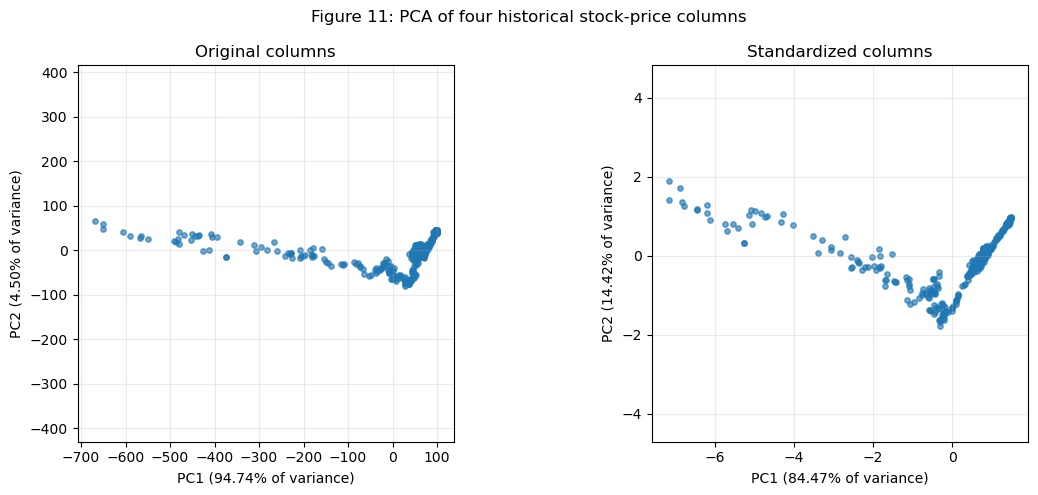

In [33]:
fig11, axes11 = plt.subplots(1, 2, figsize=(12, 5))
for axB, resultB, titleB in [
    (axes11[0], rawB, "Original columns"),
    (axes11[1], standardizedB, "Standardized columns")
]:
    axB.scatter(
        resultB["scores"][:, 0],
        resultB["scores"][:, 1],
        s=15,
        alpha=0.65
    )
    axB.set(
        xlabel=(
            f"PC1 "
            f"({100*resultB['explained'][0]:.2f}% "
            f"of variance)"
        ),
        ylabel=(
            f"PC2 "
            f"({100*resultB['explained'][1]:.2f}% "
            f"of variance)"
        ),
        title=titleB
    )
    axB.set_box_aspect(1)
    axB.set_aspect("equal", adjustable="datalim")

    axB.grid(alpha=0.25)
fig11.suptitle("Figure 11: PCA of four historical stock-price columns")
fig11.tight_layout()
plt.show()

#### Interpretation and choice of preprocessing

Principal Component Analysis (PCA) performed on raw data columns places greater emphasis on stocks with high absolute price variance—a fact reflected in their standard deviations and the coefficients of the first eigenvector. Standardizing the data ensures each column has a sample variance of one; this changes the covariance matrix, the principal directions, and the proportion of variance explained. In both approaches, the first two components capture the majority of the variance; however, because variance is measured on different scales, a higher proportion of explained variance does not necessarily imply a superior analytical outcome. To compare general patterns across four stocks without allowing price scales to dictate their relative importance, it is preferable to apply PCA to standardized data; conversely, PCA on raw data is more appropriate if the objective is to examine volatility in absolute terms (i.e., in monetary units). Furthermore, since these historical price series contain time-dependent trends, the resulting PCA serves only to describe the observed dataset and possesses no predictive capability.